## **Prova Substitutiva • Data Analytics • POSTECH (Fase 4)**
`Vinicius de Marchi Franciscon`

# Previsão do preço do petróleo Brent em dólar

Modelo preditivo para apoiar a tomada de decisão numa grande empresa de petróleo, com aplicação em Streamlit.

**Este notebook é construído por fases**, sempre no mesmo arquivo. Estão prontas a **Fase 1 (entendimento dos dados)**, a **Fase 2 (features e protocolo de validação)** e a **Fase 3 (modelagem)**. Comparação com SHAP, previsão final e aplicação entram nas fases seguintes.

| Bloco | O que responde |
|---|---|
| **1. Base** | Que dados temos, de onde vêm e se são confiáveis |
| **2. EDA do Brent** | Como o preço se comporta: altos, baixos, quedas, instabilidade e eventos |
| **3. Fatores externos** | O que o dólar e os estoques dos EUA dizem sobre o Brent |
| **4. Padrões** | Tendência, sazonalidade de calendário e memória da série |
| **5. Leitura para a modelagem** | O que a EDA decide para as próximas fases |
| **6. Features e alvo** | O que o modelo recebe (25 features), o que ele prevê e a divisão treino/validação/teste |
| **7. Protocolo e baselines** | As regras da comparação e o piso que todo modelo precisa superar |
| **8. Modelos** | Prophet e LightGBM com Optuna, avaliados na validação e, uma única vez, no teste |

**Convenções:** `VAR` = variação percentual. `DESV_PAD` = desvio padrão das VAR diárias numa janela (mede o quanto o preço balança no dia a dia). Preços em **US$ por barril**.

## Bloco 1. Base de dados

In [1]:
import os, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates, seaborn as sns
from matplotlib.lines import Line2D
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf

SEMENTE = 42
np.random.seed(SEMENTE)
H = 15                      # horizonte de previsão (dias úteis)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.32})
AZUL, VERDE, VERMELHO, CINZA, LARANJA, ROXO = "#1f4e79", "#2e7d32", "#c62828", "#616161", "#ef6c00", "#6a1b9a"

def pt(x, casas=0):
    """número no formato brasileiro (milhar com ponto, decimal com vírgula)"""
    return f"{x:,.{casas}f}".replace(",", "\x00").replace(".", ",").replace("\x00", ".")
def bolinha(cor, rotulo):
    return Line2D([], [], marker="o", ms=7.5, color=cor, ls="none", label=rotulo)
def legenda_lateral(ax, itens, titulo=None):
    ax.legend(handles=itens, loc="center left", bbox_to_anchor=(1.015, 0.5), frameon=False, fontsize=9.2, title=titulo,
              title_fontproperties={"weight": "bold", "size": 9})

# localiza 00_Base_TC a partir da pasta do notebook (funciona rodando de 01_Notebook ou da raiz)
AQUI = Path(os.getcwd())
BASE = next(p / "00_Base_TC" for p in [AQUI, AQUI.parent] if (p / "00_Base_TC").is_dir())
print(f"Pasta de dados: {BASE}")

Pasta de dados: C:\Users\vinic\OneDrive\Área de Trabalho\TC - 04 SUB\00_Base_TC


In [2]:
# 1.1 Leitura das bases
base_bruta = pd.read_parquet(BASE / "base_modelagem_diaria.parquet").sort_values("data").reset_index(drop=True)
dolar  = pd.read_parquet(BASE / "dolar_amplo_fred.parquet").sort_values("data").reset_index(drop=True)
est    = pd.read_parquet(BASE / "estoques_crude_eia.parquet").sort_values("semana_ref").reset_index(drop=True)
eia    = pd.read_parquet(BASE / "brent_eia_conferencia.parquet").sort_values("data").reset_index(drop=True)   # só conferência

# 1.2 O Ipeadata traz registros em sábado e domingo (2002 a 2018). O Brent só é negociado em dias úteis.
fds = base_bruta["data"].dt.dayofweek >= 5
print(f"Registros em fim de semana na série do Ipeadata: {fds.sum()} de {len(base_bruta)} ({fds.mean()*100:.1f}%), entre {base_bruta.loc[fds,'data'].min():%d/%m/%Y} e {base_bruta.loc[fds,'data'].max():%d/%m/%Y}")
base = base_bruta.loc[~fds].reset_index(drop=True)          # regra adotada: manter só dias úteis
print(f"Base de trabalho: {len(base)} dias úteis")

# 1.3 Verificações de sanidade
assert (base["data"].dt.dayofweek < 5).all(), "ainda há fim de semana na base"
assert base["data"].is_monotonic_increasing and base["data"].is_unique, "datas fora de ordem ou repetidas"
assert base.notna().all().all(), "há valores vazios na base"
assert (base["preco_usd"] > 0).all(), "há preços não positivos"
assert base["preco_usd"].between(5, 200).all(), "preço fora da escala plausível (US$ 5 a 200)"
assert (base["dolar_data_ref"] < base["data"]).all(), "dólar usa informação do próprio dia ou do futuro"
assert ((base["data"] - base["estoque_semana_ref"]).dt.days >= 6).all(), "estoque usado antes da divulgação"
assert ((base["data"] - base["estoque_semana_ref"]).dt.days <= 14).all(), "estoque desatualizado demais"

df = base[["data", "preco_usd"]].copy()
y, D = df["preco_usd"].values, pd.DatetimeIndex(df["data"])
df["VAR_1D"] = df["preco_usd"].pct_change() * 100
print("Todas as verificações passaram.")
display(pd.DataFrame({
    "Série": ["Brent (US$/barril)", "Dólar amplo (índice)", "Estoques de petróleo bruto EUA (mil barris)"],
    "Frequência": ["diária (dias úteis)", "diária", "semanal"],
    "Observações": [pt(len(base)), pt(len(dolar)), pt(len(est))],
    "Início": [f"{D.min():%d/%m/%Y}", f"{dolar['data'].min():%d/%m/%Y}", f"{est['semana_ref'].min():%d/%m/%Y}"],
    "Fim": [f"{D.max():%d/%m/%Y}", f"{dolar['data'].max():%d/%m/%Y}", f"{est['semana_ref'].max():%d/%m/%Y}"],
    "Fonte": ["Ipeadata (origem EIA)", "Federal Reserve / FRED", "EIA"],
}).style.hide(axis="index"))

Registros em fim de semana na série do Ipeadata: 1310 de 6634 (19.7%), entre 07/01/2006 e 12/10/2024
Base de trabalho: 5324 dias úteis
Todas as verificações passaram.


Série,Frequência,Observações,Início,Fim,Fonte
Brent (US$/barril),diária (dias úteis),5.324,03/01/2006,29/09/2026,Ipeadata (origem EIA)
Dólar amplo (índice),diária,5.203,02/01/2006,02/10/2026,Federal Reserve / FRED
Estoques de petróleo bruto EUA (mil barris),semanal,2.296,20/08/1982,25/09/2026,EIA


### 1.4 Qualidade da série do Ipeadata: o que sabemos e o que fazemos

A série do Brent no Ipeadata, que o enunciado indica, tem um **problema de datas entre 2002 e 2018**. Para dimensioná-lo, conferimos cada dia contra a série original da EIA (a fonte primária do Ipeadata). **A EIA entra aqui só como conferência. Todo o trabalho usa o Ipeadata.**

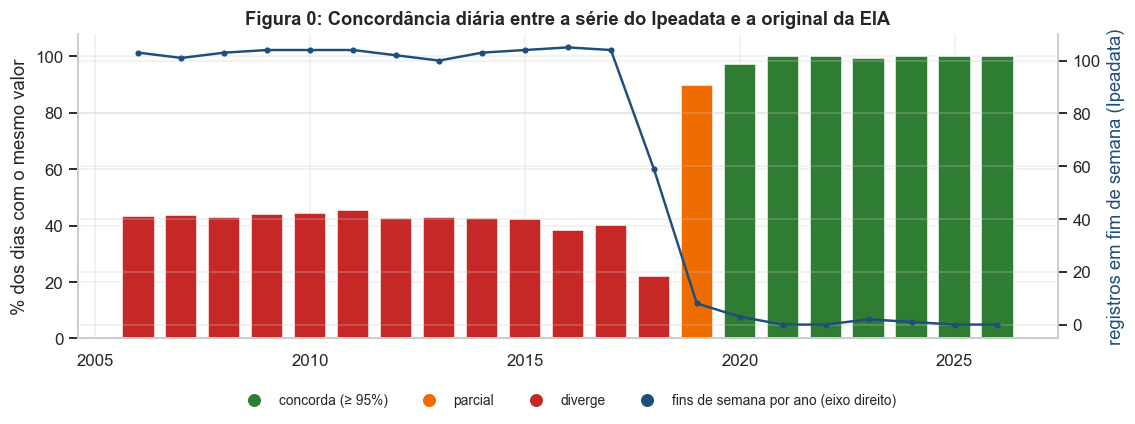

2002 a 2018: 41% dos dias batem com a EIA (n = 3250), diferença média de US$ 1.68 quando divergem
Demais anos: 98% batem (n = 1949)


In [3]:
# 1.4 Conferência Ipeadata x EIA, dia a dia
conf = base_bruta[["data", "preco_usd"]].merge(eia, on="data", how="inner")
conf["bate"] = (conf["preco_usd"] - conf["preco_eia_usd"]).abs() <= 0.005
conf["ano"] = conf["data"].dt.year
por_ano_conf = conf.groupby("ano")["bate"].mean() * 100
fds_ano = base_bruta.assign(ano=base_bruta["data"].dt.year, fds=fds).groupby("ano")["fds"].sum()

fig, ax = plt.subplots(figsize=(11.5, 3.6))
ax.bar(por_ano_conf.index, por_ano_conf.values, color=[VERDE if v >= 95 else (LARANJA if v >= 60 else VERMELHO) for v in por_ano_conf.values], width=0.75)
ax.set_ylim(0, 108); ax.set_ylabel("% dos dias com o mesmo valor")
ax.set_title("Figura 0: Concordância diária entre a série do Ipeadata e a original da EIA")
ax2 = ax.twinx(); ax2.plot(fds_ano.index, fds_ano.values, color=AZUL, lw=1.6, marker="o", ms=3); ax2.set_ylabel("registros em fim de semana (Ipeadata)", color=AZUL); ax2.spines["right"].set_visible(True)
ax.legend(handles=[bolinha(VERDE, "concorda (≥ 95%)"), bolinha(LARANJA, "parcial"), bolinha(VERMELHO, "diverge"), bolinha(AZUL, "fins de semana por ano (eixo direito)")], loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, frameon=False, fontsize=9)
plt.show()
ruim = conf[(conf["ano"] >= 2002) & (conf["ano"] <= 2018)]
bons = conf[(conf["ano"] < 2002) | (conf["ano"] > 2018)]
print(f"2002 a 2018: {ruim['bate'].mean()*100:.0f}% dos dias batem com a EIA (n = {len(ruim)}), diferença média de US$ {(ruim.loc[~ruim['bate'],'preco_usd'] - ruim.loc[~ruim['bate'],'preco_eia_usd']).abs().mean():.2f} quando divergem")
print(f"Demais anos: {bons['bate'].mean()*100:.0f}% batem (n = {len(bons)})")

In [4]:
# 1.5 O defeito não é só de data: ele muda as estatísticas da série (VAR diária, dias úteis)
def estat(serie):
    r = serie.pct_change().dropna() * 100
    return {"Dias": len(r), "DESV_PAD da VAR diária (%)": r.std(), "Autocorrelação em 1 dia": r.autocorr(1), "Dias com |VAR| > 5% (%)": (r.abs() > 5).mean() * 100}
ip, ee = base.set_index("data")["preco_usd"], eia.set_index("data")["preco_eia_usd"]
linhas = []
for nome, i0, i1 in [("2006 a 2018", "2006-01-01", "2018-12-31"), ("2019 a 2026", "2019-01-01", "2026-12-31")]:
    for fonte, ser in [("Ipeadata (usado)", ip), ("EIA (conferência)", ee)]:
        linhas.append({"Período": nome, "Fonte": fonte, **estat(ser[i0:i1])})
IMPACTO = pd.DataFrame(linhas)
display(IMPACTO.style.hide(axis="index").format({"DESV_PAD da VAR diária (%)": "{:.2f}", "Autocorrelação em 1 dia": "{:+.3f}", "Dias com |VAR| > 5% (%)": "{:.1f}"}))

Período,Fonte,Dias,DESV_PAD da VAR diária (%),Autocorrelação em 1 dia,Dias com |VAR| > 5% (%)
2006 a 2018,Ipeadata (usado),3361,2.95,-0.338,8.1
2006 a 2018,EIA (conferência),3252,2.15,+0.017,3.1
2019 a 2026,Ipeadata (usado),1961,3.46,-0.025,6.6
2019 a 2026,EIA (conferência),1962,3.42,-0.020,6.4


**Leitura da tabela.** De 2019 em diante as duas séries são equivalentes. De 2006 a 2018, a do Ipeadata aparenta ser mais instável (DESV_PAD diário maior, mais dias com variação acima de 5%) e mostra uma **autocorrelação negativa forte em 1 dia** (o dia seguinte tende a desfazer o movimento anterior). A série original da EIA não tem isso. É um efeito fabricado pelos valores deslocados, **não uma propriedade do mercado**.

**Consequência para o projeto.** Tudo o que for medido com a VAR diária de 2006 a 2018 neste notebook (distribuição, DESV_PAD, autocorrelação, regimes de instabilidade) deve ser lido com essa ressalva. Na Fase 2 será preciso decidir como treinar o modelo diante disso, e levaremos essa decisão a você.

**O que fazemos com isso.**
- **Removemos os fins de semana**, para que "dia útil" tenha o significado correto no horizonte de 15 dias e no calendário.
- **Mantemos o Ipeadata como fonte**, conforme o enunciado. Os valores deslocados dentro dos dias úteis de 2002 a 2018 continuam na base.
- **Registramos a limitação.** Ela afeta a medida das oscilações diárias nesse período (ver 1.5) e o alinhamento fino com o dólar e os estoques. O período de 2019 em diante, que pesa mais para a previsão atual, está limpo.
- **Teste de sensibilidade (Fase 4).** Rodaremos o modelo final também com a série da EIA e compararemos, para saber se a conclusão depende desse defeito.

**Como a base de dólar e estoques foi montada (sem vazamento do futuro).** Cada linha é um dia de cotação do Brent. O dólar é o valor do dia útil **anterior** (D-1) e o estoque é o último **já divulgado** (a EIA publica na quarta-feira seguinte ao fim da semana; usamos a quinta, por segurança). As verificações acima garantem isso. Fontes e licenças em `00_Base_TC/FONTES.md`.

**Escolha de recorte.** Usamos de **jan/2006** em diante: é onde o dólar amplo do Federal Reserve começa, e inclui os grandes regimes recentes (crise de 2008, colapso de 2014-16, COVID, Ucrânia e o choque de 2026).

In [5]:
# 1.3 Estatísticas gerais do Brent
dd_serie = (df["preco_usd"] / df["preco_usd"].cummax() - 1) * 100
resumo = pd.DataFrame({
    "Métrica": ["Dias de cotação", "Período", "Preço mínimo", "Preço máximo", "Mediana", "Último preço",
                "VAR diária média", "DESV_PAD da VAR diária"],
    "Valor": [pt(len(df)), f"{D.min():%d/%m/%Y} a {D.max():%d/%m/%Y}",
              f"US$ {pt(y.min(), 2)} em {D[y.argmin()]:%d/%m/%Y}", f"US$ {pt(y.max(), 2)} em {D[y.argmax()]:%d/%m/%Y}",
              f"US$ {pt(np.median(y), 2)}", f"US$ {pt(y[-1], 2)} em {D[-1]:%d/%m/%Y}",
              f"{pt(df['VAR_1D'].mean(), 3)}%", f"{pt(df['VAR_1D'].std(), 2)}%"]})
display(resumo.style.hide(axis="index"))

Métrica,Valor
Dias de cotação,5.324
Período,03/01/2006 a 29/09/2026
Preço mínimo,"US$ 9,12 em 21/04/2020"
Preço máximo,"US$ 143,95 em 03/07/2008"
Mediana,"US$ 74,33"
Último preço,"US$ 113,96 em 29/09/2026"
VAR diária média,"0,062%"
DESV_PAD da VAR diária,"3,15%"


## Bloco 2. Análise exploratória do Brent

### 2.1 Eventos que movem o petróleo

A tabela abaixo reúne os eventos usados para **contextualizar** altos, baixos e quedas. Ela é uma entrada manual e transparente: cada linha tem categoria e origem da informação.

> **Nota de verificação:** a coluna `verificacao` indica a origem. "dado da série" = conferido nos preços; "web (pesquisa)" = consultado em fonte web durante o projeto (jornalismo e EIA); "conhecimento geral" = fato amplamente documentado, **sem checagem de fonte neste projeto**. Confirme as datas antes de citá-las como fato na apresentação.

In [6]:
# 2.1 Tabela de eventos (entrada manual e rastreável)
EV = [
 # data,        sentido,  categoria,       evento,                                                              verificação
 ("2008-07-03", "alta",   "mercado",       "Máximo histórico do período: US$ 143,95 (demanda forte, dólar fraco, pouca capacidade ociosa)", "dado da série"),
 ("2008-09-15", "queda",  "financeiro",    "Falência do Lehman Brothers: crise financeira global e colapso da demanda",                      "conhecimento geral"),
 ("2008-12-17", "alta",   "OPEP",          "OPEP anuncia corte de 2,2 milhões de barris/dia para frear a queda",                            "conhecimento geral"),
 ("2011-02-22", "alta",   "geopolítica",   "Primavera Árabe: revolta e interrupção da produção na Líbia",                                   "conhecimento geral"),
 ("2014-06-19", "queda",  "oferta",        "Topo de 2014 (US$ 115); começa o colapso por excesso de oferta (shale oil dos EUA)",            "dado da série"),
 ("2014-11-27", "queda",  "OPEP",          "OPEP decide não cortar produção: guerra por participação de mercado",                          "conhecimento geral"),
 ("2016-01-20", "queda",  "oferta",        "Mínimo do ciclo 2014-16: US$ 26 por excesso de oferta e estoques cheios",                       "dado da série"),
 ("2016-11-30", "alta",   "OPEP",          "Acordo OPEP+ de corte de produção",                                                             "conhecimento geral"),
 ("2018-10-05", "alta",   "geopolítica",   "Topo de 2018 (US$ 86), com sanções dos EUA ao Irã no radar; depois cai com oferta forte",       "dado da série"),
 ("2020-03-06", "queda",  "OPEP",          "Fracasso do acordo OPEP+ e guerra de preços Arábia Saudita x Rússia, em meio à COVID-19",       "conhecimento geral"),
 ("2020-03-11", "queda",  "demanda",       "OMS declara a pandemia de COVID-19: demanda global despenca",                                   "conhecimento geral"),
 ("2020-04-12", "alta",   "OPEP",          "Acordo OPEP+ de corte histórico de 9,7 milhões de barris/dia",                                  "conhecimento geral"),
 ("2020-04-21", "queda",  "demanda",       "Mínimo da série (US$ 9,12), um dia após o WTI fechar negativo",                                 "dado da série"),
 ("2022-02-24", "alta",   "geopolítica",   "Rússia invade a Ucrânia: risco sobre a oferta russa",                                           "conhecimento geral"),
 ("2022-03-08", "alta",   "geopolítica",   "Pico do choque (US$ 133); EUA anunciam veto ao petróleo russo",                                 "conhecimento geral"),
 ("2025-04-02", "queda",  "demanda",       "Tarifas dos EUA ('Dia da Libertação') pressionam a demanda; OPEP+ já devolve cortes a partir de maio", "conhecimento geral"),
 ("2025-06-13", "alta",   "geopolítica",   "Israel ataca o Irã (guerra de 12 dias)",                                                        "web (pesquisa)"),
 ("2025-06-24", "queda",  "geopolítica",   "Cessar-fogo Israel-Irã: o prêmio de risco some em poucos dias",                                 "conhecimento geral"),
 ("2026-03-02", "alta",   "geopolítica",   "Guerra com o Irã e fechamento do Estreito de Ormuz: Brent salta mais de 10% em um dia",         "web (pesquisa)"),
 ("2026-04-08", "queda",  "geopolítica",   "Cessar-fogo EUA-Irã anunciado, embora o tráfego no estreito siga baixo",                        "web (pesquisa)"),
 ("2026-07-08", "alta",   "geopolítica",   "EUA voltam a atacar o Irã e revertem a queda para níveis de pré-guerra",                        "web (pesquisa)"),
 ("2026-09-28", "alta",   "geopolítica",   "EUA rejeitam proposta do Irã de reabrir o Estreito de Ormuz",                                   "web (pesquisa)"),
]
eventos = pd.DataFrame(EV, columns=["data", "sentido", "categoria", "evento", "verificacao"])
eventos["data"] = pd.to_datetime(eventos["data"])
# eventos em feriado ou fim de semana (ex.: Ação de Graças, domingo) valem a partir do primeiro pregão seguinte
POS = D.searchsorted(eventos["data"])
assert ((pd.Series(D[POS]) - eventos["data"]).dt.days <= 4).all(), "evento longe de qualquer cotação"

# estudo de evento: VAR do Brent nos 5 e 20 pregões a partir do evento, contra o fechamento do pregão anterior
linhas = []
for (_, e), i0 in zip(eventos.iterrows(), POS):
    ref = y[i0 - 1]
    linhas.append({"Data": f"{e['data']:%d/%m/%Y}", "Sentido": e["sentido"], "Categoria": e["categoria"],
                   "Preço antes (US$)": ref,
                   "VAR dia (%)": (y[i0] / ref - 1) * 100,
                   "VAR 5 pregões (%)": (y[i0 + 4] / ref - 1) * 100 if i0 + 4 < len(y) else np.nan,
                   "VAR 20 pregões (%)": (y[i0 + 19] / ref - 1) * 100 if i0 + 19 < len(y) else np.nan,
                   "Origem": e["verificacao"], "Evento": e["evento"][:92]})
EST_EV = pd.DataFrame(linhas)
display(EST_EV.style.hide(axis="index").format({"Preço antes (US$)": "{:.2f}", "VAR dia (%)": "{:+.1f}", "VAR 5 pregões (%)": "{:+.1f}", "VAR 20 pregões (%)": "{:+.1f}"}, na_rep="—"))

Data,Sentido,Categoria,Preço antes (US$),VAR dia (%),VAR 5 pregões (%),VAR 20 pregões (%),Origem,Evento
03/07/2008,alta,mercado,141.24,+1.9,-5.2,-13.3,dado da série,"Máximo histórico do período: US$ 143,95 (demanda forte, dólar fraco, pouca capacidade ociosa"
15/09/2008,queda,financeiro,101.08,-5.0,-10.5,-16.2,conhecimento geral,Falência do Lehman Brothers: crise financeira global e colapso da demanda
17/12/2008,alta,OPEP,42.38,-1.3,-6.7,-0.1,conhecimento geral,"OPEP anuncia corte de 2,2 milhões de barris/dia para frear a queda"
22/02/2011,alta,geopolítica,103.45,-1.2,+10.1,+10.4,conhecimento geral,Primavera Árabe: revolta e interrupção da produção na Líbia
19/06/2014,queda,oferta,114.25,+0.8,-1.2,-7.7,dado da série,Topo de 2014 (US$ 115); começa o colapso por excesso de oferta (shale oil dos EUA)
27/11/2014,queda,OPEP,77.39,+2.9,-11.5,-24.7,conhecimento geral,OPEP decide não cortar produção: guerra por participação de mercado
20/01/2016,queda,oferta,28.80,-9.7,+5.8,+10.4,dado da série,Mínimo do ciclo 2014-16: US$ 26 por excesso de oferta e estoques cheios
30/11/2016,alta,OPEP,44.68,+7.3,+17.1,+20.7,conhecimento geral,Acordo OPEP+ de corte de produção
05/10/2018,alta,geopolítica,85.45,+0.7,-1.9,-12.4,dado da série,"Topo de 2018 (US$ 86), com sanções dos EUA ao Irã no radar; depois cai com oferta forte"
06/03/2020,queda,OPEP,51.29,-11.1,-39.5,-60.5,conhecimento geral,"Fracasso do acordo OPEP+ e guerra de preços Arábia Saudita x Rússia, em meio à COVID-19"


### 2.2 O preço ao longo do tempo: altos, baixos e eventos

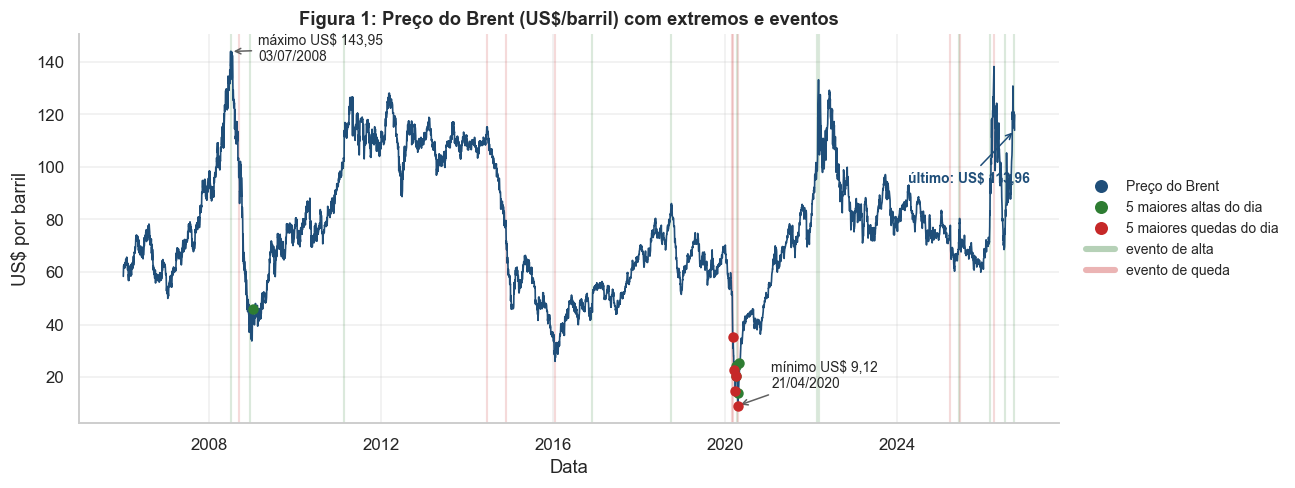

Tipo,Data,Preço (US$),VAR dia (%)
alta,22/04/2020,13.77,+51.0
alta,02/04/2020,20.24,+35.2
alta,05/01/2009,45.84,+34.2
alta,05/05/2020,25.46,+24.8
alta,03/04/2020,24.33,+20.2
queda,21/04/2020,9.12,-47.5
queda,31/03/2020,14.85,-22.6
queda,09/03/2020,35.33,-22.5
queda,09/04/2020,20.23,-19.8
queda,18/03/2020,22.79,-18.5


In [7]:
# 2.2 Figura 1: série completa, extremos, eventos e regimes
altas  = df.dropna(subset=["VAR_1D"]).nlargest(5, "VAR_1D")
baixas = df.dropna(subset=["VAR_1D"]).nsmallest(5, "VAR_1D")

fig, ax = plt.subplots(figsize=(11.5, 4.6))
ax.plot(D, y, color=AZUL, lw=1.1, zorder=3)
for _, e in eventos.iterrows():
    ax.axvline(e["data"], color=VERDE if e["sentido"] == "alta" else VERMELHO, alpha=0.17, lw=1.4, zorder=1)
ax.scatter(altas["data"],  altas["preco_usd"],  color=VERDE,    s=34, zorder=5)
ax.scatter(baixas["data"], baixas["preco_usd"], color=VERMELHO, s=34, zorder=5)
i_max, i_min = int(np.argmax(y)), int(np.argmin(y))
ax.annotate(f"máximo US$ {pt(y[i_max],2)}\n{D[i_max]:%d/%m/%Y}", (D[i_max], y[i_max]), xytext=(18, -6), textcoords="offset points",
            fontsize=9, arrowprops=dict(arrowstyle="->", color=CINZA))
ax.annotate(f"mínimo US$ {pt(y[i_min],2)}\n{D[i_min]:%d/%m/%Y}", (D[i_min], y[i_min]), xytext=(22, 12), textcoords="offset points",
            fontsize=9, arrowprops=dict(arrowstyle="->", color=CINZA))
ax.annotate(f"último: US$ {pt(y[-1],2)}", (D[-1], y[-1]), xytext=(-70, -34), textcoords="offset points", fontsize=9, color=AZUL, fontweight="bold", arrowprops=dict(arrowstyle="->", color=AZUL))
ax.set_title("Figura 1: Preço do Brent (US$/barril) com extremos e eventos")
ax.set_xlabel("Data"); ax.set_ylabel("US$ por barril")
legenda_lateral(ax, [bolinha(AZUL, "Preço do Brent"), bolinha(VERDE, "5 maiores altas do dia"), bolinha(VERMELHO, "5 maiores quedas do dia"),
                     Line2D([], [], color=VERDE, lw=4, alpha=0.35, label="evento de alta"), Line2D([], [], color=VERMELHO, lw=4, alpha=0.35, label="evento de queda")])
plt.show()

display(pd.concat([
    altas.assign(Tipo="alta")[["Tipo", "data", "preco_usd", "VAR_1D"]],
    baixas.assign(Tipo="queda")[["Tipo", "data", "preco_usd", "VAR_1D"]]]).rename(
    columns={"data": "Data", "preco_usd": "Preço (US$)", "VAR_1D": "VAR dia (%)"}).assign(Data=lambda d: d["Data"].dt.strftime("%d/%m/%Y")).style.hide(axis="index").format({"Preço (US$)": "{:.2f}", "VAR dia (%)": "{:+.1f}"}))

### 2.3 Ano a ano

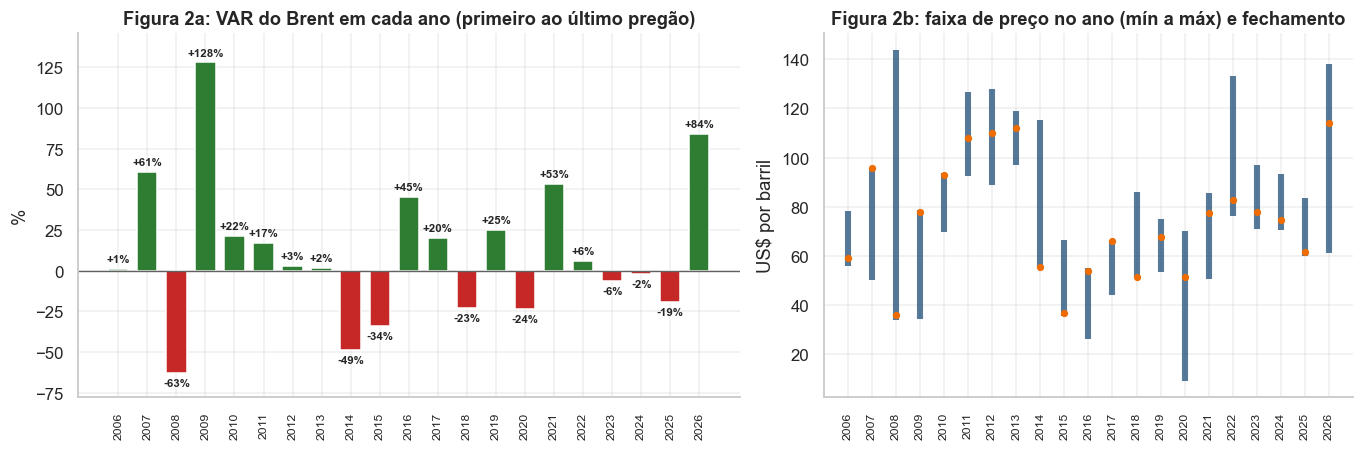

,Abertura ano,Fechamento ano,Mín,Máx,Dias,DESV_PAD dia (%),VAR ano (%)
ano,,,,,,,
2006,58.34,58.96,55.82,78.26,259,2.88,1.06
2007,59.41,95.66,49.95,95.66,258,2.45,61.02
2008,95.92,35.82,33.73,143.95,260,4.61,-62.66
2009,34.16,77.91,34.16,78.64,259,4.37,128.07
2010,76.59,93.08,69.56,93.63,260,2.57,21.53
2011,92.50,108.09,92.50,126.64,258,2.56,16.85
2012,106.89,110.04,88.69,128.08,257,2.19,2.95
2013,110.05,112.06,96.84,118.90,257,1.59,1.83
2014,107.94,55.27,55.27,115.19,258,1.85,-48.80


In [8]:
# 2.3 Figura 2: VAR por ano e faixa de preço
por_ano = df.assign(ano=D.year).groupby("ano").agg(inicio=("preco_usd", "first"), fim=("preco_usd", "last"),
                                                   minimo=("preco_usd", "min"), maximo=("preco_usd", "max"),
                                                   dias=("preco_usd", "size"), DESV_PAD_dia=("VAR_1D", "std"))
por_ano["VAR_ano"] = (por_ano["fim"] / por_ano["inicio"] - 1) * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
barras = a1.bar(por_ano.index.astype(str), por_ano["VAR_ano"], color=[VERDE if v > 0 else VERMELHO for v in por_ano["VAR_ano"]], width=0.7)
for b, v in zip(barras, por_ano["VAR_ano"]):
    a1.text(b.get_x() + b.get_width()/2, v + (3 if v > 0 else -3), f"{v:+.0f}%", ha="center", va="bottom" if v > 0 else "top", fontsize=7.5, fontweight="bold")
a1.axhline(0, color=CINZA, lw=0.9)
a1.set_title("Figura 2a: VAR do Brent em cada ano (primeiro ao último pregão)"); a1.set_ylabel("%")
a1.tick_params(axis="x", rotation=90, labelsize=8); a1.set_ylim(por_ano["VAR_ano"].min() - 15, por_ano["VAR_ano"].max() + 18)
a2.vlines(por_ano.index.astype(str), por_ano["minimo"], por_ano["maximo"], color=AZUL, lw=4, alpha=0.75)
a2.scatter(por_ano.index.astype(str), por_ano["fim"], color=LARANJA, s=14, zorder=3)
a2.set_title("Figura 2b: faixa de preço no ano (mín a máx) e fechamento"); a2.set_ylabel("US$ por barril")
a2.tick_params(axis="x", rotation=90, labelsize=8)
plt.tight_layout(); plt.show()
display(por_ano.round(2).rename(columns={"inicio": "Abertura ano", "fim": "Fechamento ano", "minimo": "Mín", "maximo": "Máx", "dias": "Dias", "DESV_PAD_dia": "DESV_PAD dia (%)", "VAR_ano": "VAR ano (%)"}))

### 2.4 Como são as variações diárias

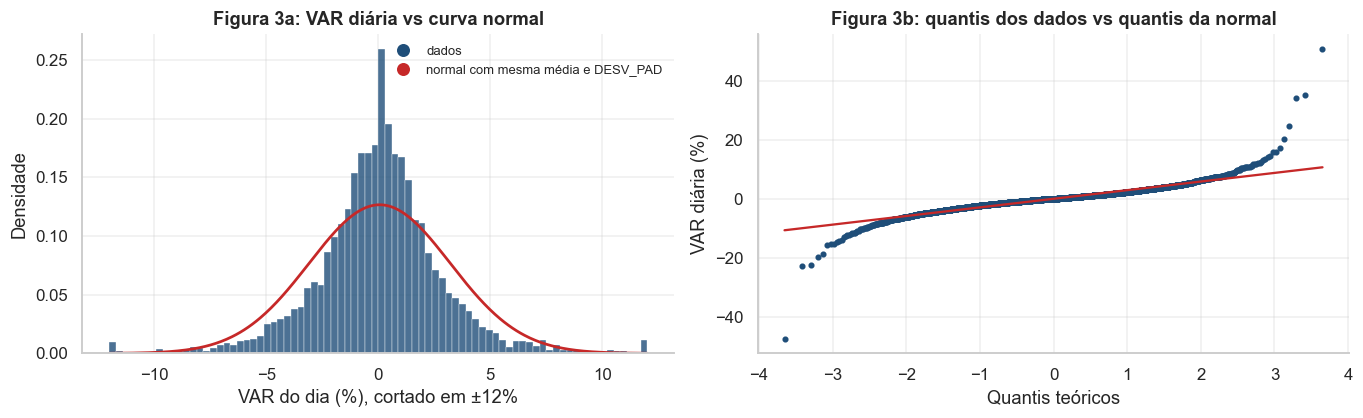

VAR diária: média +0.062%, DESV_PAD 3.15%, assimetria 0.57, curtose 32.0 (normal = 0)
Dias a mais de 3 DESV_PAD da média: 1.26% (normal: 0,27%)
Dias com |VAR| > 5%: 401 de 5323 (7.5%)


In [9]:
# 2.4 Figura 3: distribuição da VAR diária (cauda gorda)
r = df["VAR_1D"].dropna()
mu, sd = r.mean(), r.std()
assim, curt = r.skew(), r.kurt()
dentro_3dp = (np.abs(r - mu) <= 3 * sd).mean() * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 3.9))
cortada = r.clip(-12, 12)
a1.hist(cortada, bins=80, density=True, color=AZUL, alpha=0.8, edgecolor="white", linewidth=0.3)
xx = np.linspace(-12, 12, 400); a1.plot(xx, stats.norm.pdf(xx, mu, sd), color=VERMELHO, lw=1.8)
a1.set_title("Figura 3a: VAR diária vs curva normal"); a1.set_xlabel("VAR do dia (%), cortado em ±12%"); a1.set_ylabel("Densidade")
a1.legend(handles=[bolinha(AZUL, "dados"), bolinha(VERMELHO, "normal com mesma média e DESV_PAD")], frameon=False, fontsize=8.5, loc="upper right")
stats.probplot(r, dist="norm", plot=a2)
a2.get_lines()[0].set_markersize(3); a2.get_lines()[0].set_color(AZUL); a2.get_lines()[1].set_color(VERMELHO)
a2.set_title("Figura 3b: quantis dos dados vs quantis da normal"); a2.set_xlabel("Quantis teóricos"); a2.set_ylabel("VAR diária (%)")
plt.tight_layout(); plt.show()
print(f"VAR diária: média {mu:+.3f}%, DESV_PAD {sd:.2f}%, assimetria {assim:.2f}, curtose {curt:.1f} (normal = 0)")
print(f"Dias a mais de 3 DESV_PAD da média: {100-dentro_3dp:.2f}% (normal: 0,27%)")
print(f"Dias com |VAR| > 5%: {(r.abs() > 5).sum()} de {len(r)} ({(r.abs() > 5).mean()*100:.1f}%)")

### 2.5 Queda desde a máxima de 12 meses

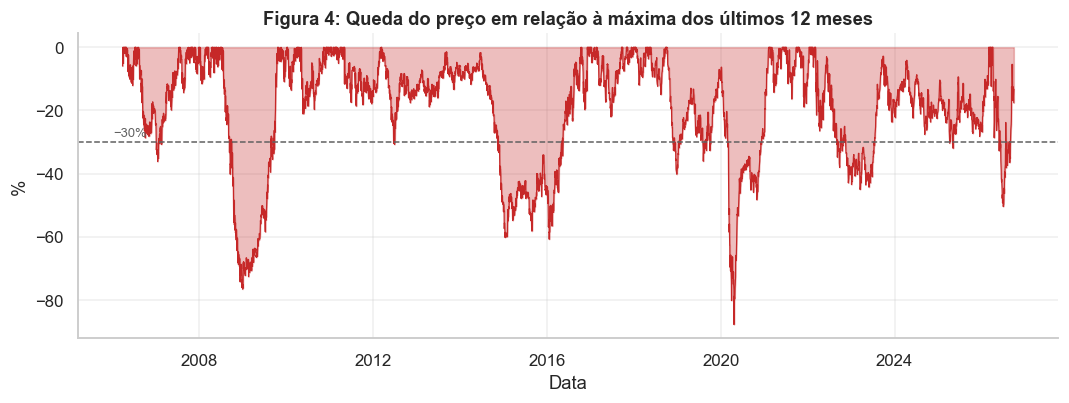

Topo,Fundo,Preço topo (US$),Preço fundo (US$),Queda (%),Pregões do topo ao fundo
09/08/2006,16/01/2007,78.26,49.95,-36.2,114
03/07/2008,30/12/2008,143.95,33.73,-76.6,126
13/03/2012,29/06/2012,128.08,88.69,-30.8,78
13/05/2015,20/01/2016,66.33,26.01,-60.8,180
05/10/2018,27/12/2018,86.07,51.49,-40.2,56
16/05/2019,21/04/2020,74.70,9.12,-87.8,239
08/06/2022,17/03/2023,129.20,71.03,-45.0,200
05/07/2024,07/05/2025,88.66,60.31,-32.0,209
07/04/2026,02/07/2026,138.21,68.53,-50.4,60


Queda mais profunda em 12 meses: -87.8% em 21/04/2020
Máximo de 2008 (US$ 143,95) nunca foi recuperado: o pico de 2026 foi US$ 138,21


In [10]:
# 2.5 Figura 4: queda desde a máxima móvel de 252 pregões (~12 meses) e episódios
J = 252
maxj = df["preco_usd"].rolling(J, min_periods=60).max()
df["QUEDA_12M"] = (df["preco_usd"] / maxj - 1) * 100

# episódios: dias com queda <= -30%, agrupados quando separados por menos de 30 pregões
marc = (df["QUEDA_12M"] <= -30).values
episodios, i = [], 0
while i < len(marc):
    if marc[i]:
        j = i
        while j + 1 < len(marc) and (marc[j+1:j+31].any()): 
            j = j + 1 + int(np.argmax(marc[j+1:j+31]))
        seg = slice(i, j + 1)
        t = i + int(np.argmin(df["QUEDA_12M"].values[seg]))
        p = max(0, t - J) + int(np.argmax(y[max(0, t - J):t + 1]))
        episodios.append({"Topo": f"{D[p]:%d/%m/%Y}", "Fundo": f"{D[t]:%d/%m/%Y}", "Preço topo (US$)": y[p], "Preço fundo (US$)": y[t],
                          "Queda (%)": (y[t] / y[p] - 1) * 100, "Pregões do topo ao fundo": t - p})
        i = j + 1
    else:
        i += 1
EPIS = pd.DataFrame(episodios)
EPIS = (EPIS.sort_values('Queda (%)').drop_duplicates('Topo').assign(_d=lambda d: pd.to_datetime(d['Topo'], format='%d/%m/%Y')).sort_values('_d').drop(columns='_d').reset_index(drop=True))

fig, ax = plt.subplots(figsize=(11.5, 3.6))
ax.fill_between(D, df["QUEDA_12M"], 0, color=VERMELHO, alpha=0.30)
ax.plot(D, df["QUEDA_12M"], color=VERMELHO, lw=0.8)
ax.axhline(-30, color=CINZA, ls="--", lw=1); ax.text(D[5], -29, "−30%", color=CINZA, fontsize=8.5, va="bottom")
ax.set_title("Figura 4: Queda do preço em relação à máxima dos últimos 12 meses"); ax.set_xlabel("Data"); ax.set_ylabel("%")
plt.show()
display(EPIS.style.hide(axis="index").format({"Preço topo (US$)": "{:.2f}", "Preço fundo (US$)": "{:.2f}", "Queda (%)": "{:.1f}"}))
print(f"Queda mais profunda em 12 meses: {df['QUEDA_12M'].min():.1f}% em {D[int(df['QUEDA_12M'].idxmin())]:%d/%m/%Y}")
print(f"Máximo de 2008 (US$ 143,95) nunca foi recuperado: o pico de 2026 foi US$ {pt(df.loc[D.year == 2026, 'preco_usd'].max(), 2)}")

### 2.6 Instabilidade do preço: DESV_PAD de 30 dias

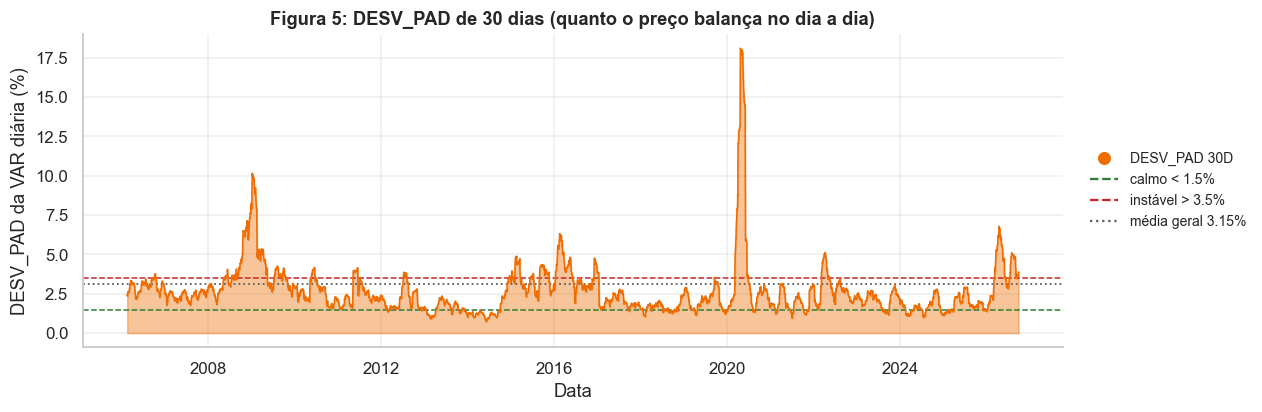

,Dias,% dos dias,|VAR| média em 15 pregões (%),"VAR 15 pregões, p10 (%)","VAR 15 pregões, p90 (%)"
regime,,,,,
calmo,761,14.42,4.68,-8.35,6.26
moderado,3663,69.39,6.55,-9.45,10.33
instável,855,16.20,11.23,-15.59,17.01


DESV_PAD 30D hoje: 3.90% (instável); média histórica 2.67%; máximo 18.1% em 23/04/2020


In [11]:
# 2.6 Figura 5: DESV_PAD 30D e regimes
df["DESV_PAD_30D"] = df["VAR_1D"].rolling(30).std()
q_calmo, q_alto = 1.5, 3.5   # cortes em % ao dia
df["regime"] = pd.cut(df["DESV_PAD_30D"], [-np.inf, q_calmo, q_alto, np.inf], labels=["calmo", "moderado", "instável"])

fig, ax = plt.subplots(figsize=(11.5, 3.7))
ax.fill_between(D, df["DESV_PAD_30D"], color=LARANJA, alpha=0.40, zorder=2)
ax.plot(D, df["DESV_PAD_30D"], color=LARANJA, lw=1.0, zorder=3)
ax.axhline(q_calmo, color=VERDE, ls="--", lw=1); ax.axhline(q_alto, color=VERMELHO, ls="--", lw=1)
ax.axhline(df["VAR_1D"].std(), color=CINZA, ls=":", lw=1.2)
ax.set_title("Figura 5: DESV_PAD de 30 dias (quanto o preço balança no dia a dia)")
ax.set_xlabel("Data"); ax.set_ylabel("DESV_PAD da VAR diária (%)")
legenda_lateral(ax, [bolinha(LARANJA, "DESV_PAD 30D"), Line2D([], [], color=VERDE, ls="--", label=f"calmo < {q_calmo}%"),
                     Line2D([], [], color=VERMELHO, ls="--", label=f"instável > {q_alto}%"),
                     Line2D([], [], color=CINZA, ls=":", label=f"média geral {df['VAR_1D'].std():.2f}%")])
plt.show()

# o que o regime muda no horizonte de previsão: quanto o preço anda em 15 pregões
df["VAR_15D_FUT"] = (df["preco_usd"].shift(-H) / df["preco_usd"] - 1) * 100
tab = df.dropna(subset=["DESV_PAD_30D", "VAR_15D_FUT"]).groupby("regime", observed=True).agg(
    dias=("preco_usd", "size"), perc=("preco_usd", lambda s: len(s)), VAR15_media_abs=("VAR_15D_FUT", lambda s: s.abs().mean()),
    VAR15_p10=("VAR_15D_FUT", lambda s: s.quantile(0.10)), VAR15_p90=("VAR_15D_FUT", lambda s: s.quantile(0.90)))
tab["perc"] = tab["dias"] / tab["dias"].sum() * 100
display(tab.rename(columns={"dias": "Dias", "perc": "% dos dias", "VAR15_media_abs": "|VAR| média em 15 pregões (%)",
                            "VAR15_p10": "VAR 15 pregões, p10 (%)", "VAR15_p90": "VAR 15 pregões, p90 (%)"}).round(2))
print(f"DESV_PAD 30D hoje: {df['DESV_PAD_30D'].iloc[-1]:.2f}% ({df['regime'].iloc[-1]}); média histórica {df['DESV_PAD_30D'].mean():.2f}%; máximo {df['DESV_PAD_30D'].max():.1f}% em {D[int(df['DESV_PAD_30D'].idxmax())]:%d/%m/%Y}")

### 2.7 O que a EDA do Brent diz

**1. O preço é dominado por regimes e choques, não por um ritmo regular.** Houve **nove quedas de 30% ou mais em 12 meses** em 20 anos. As mais fundas: 2008 (de US$ 143,95 a US$ 33,73, **−76,6% em 126 pregões**), 2015-16 (−60,8%) e 2020 (**−87,8%**, com o mínimo de US$ 9,12 em 21/04/2020). O máximo de 2008 nunca foi recuperado. Em 2026 o preço foi de US$ 62 a **US$ 138,21 (07/04)**, caiu 50% até 02/07 (US$ 68,53) e voltou a US$ 113,96 em 29/09. Um modelo que só olha o passado recente enxerga a calma entre choques e erra nos choques.

**2. A reação aos eventos é grande, mas varia muito e muitas vezes vem em dias, não no mesmo dia.**
- Ruptura da OPEP+ e COVID (06/03/2020): −11,1% no dia, **−39,5% em 5 pregões**.
- Invasão da Ucrânia (24/02/2022): +2,0% no dia, **+19,8% em 5 pregões**.
- Ormuz fechado (02/03/2026): +8,3% no dia, **+34,2% em 5 pregões**, +70,3% em 20.
- Cessar-fogo EUA-Irã (08/04/2026): **−11,6% no dia**, −25,0% em 20 pregões.
- Um corte da OPEP em dez/2008 **não** reverteu a queda (−6,7% em 5 pregões): quando a demanda cai, o anúncio pesa menos que o mercado.
- Consequência: eventos explicam *por que* o preço se moveu, mas **chegam sem aviso** e são difíceis de usar como variável de previsão.

**3. As variações diárias têm cauda gorda.** A VAR diária tem curtose 32 (normal = 0), 7,5% dos dias passam de ±5% e 1,26% dos dias passam de 3 DESV_PAD (a normal prevê 0,27%). Uma faixa de erro tirada de tabela normal ficaria curta nos choques. *Ressalva: parte desse excesso vem de 2020 e do defeito do Ipeadata em 2006-2018 (ver 1.5).*

**4. A instabilidade vem em ondas, e isso é o que mais importa para o horizonte de 15 dias.** Separando os dias pelo DESV_PAD de 30 dias, o tamanho do movimento nos 15 pregões seguintes é muito diferente:

| Regime (DESV_PAD 30D) | % dos dias | \|VAR\| média em 15 pregões | faixa p10 a p90 |
|---|---|---|---|
| calmo (< 1,5%) | 14% | 4,7% | −8,4% a +6,3% |
| moderado (1,5% a 3,5%) | 69% | 6,6% | −9,5% a +10,3% |
| **instável (> 3,5%)** | 16% | **11,2%** | **−15,6% a +17,0%** |

**Hoje o DESV_PAD de 30 dias é 3,90% (regime instável), contra 2,67% de média histórica.** Em regime instável, o preço costuma andar mais de 11% em 15 pregões. Qualquer previsão feita agora precisa de faixa larga.

## Bloco 3. Fatores externos: dólar e estoques dos EUA

Pergunta central: **dá para usar o dólar e os estoques para antecipar o Brent?** Aqui separamos duas ideias que costumam se misturar: o que *anda junto* no mesmo dia (relação contemporânea) e o que *avisa antes* (relação defasada, a única útil para prever).

### 3.1 Brent e dólar

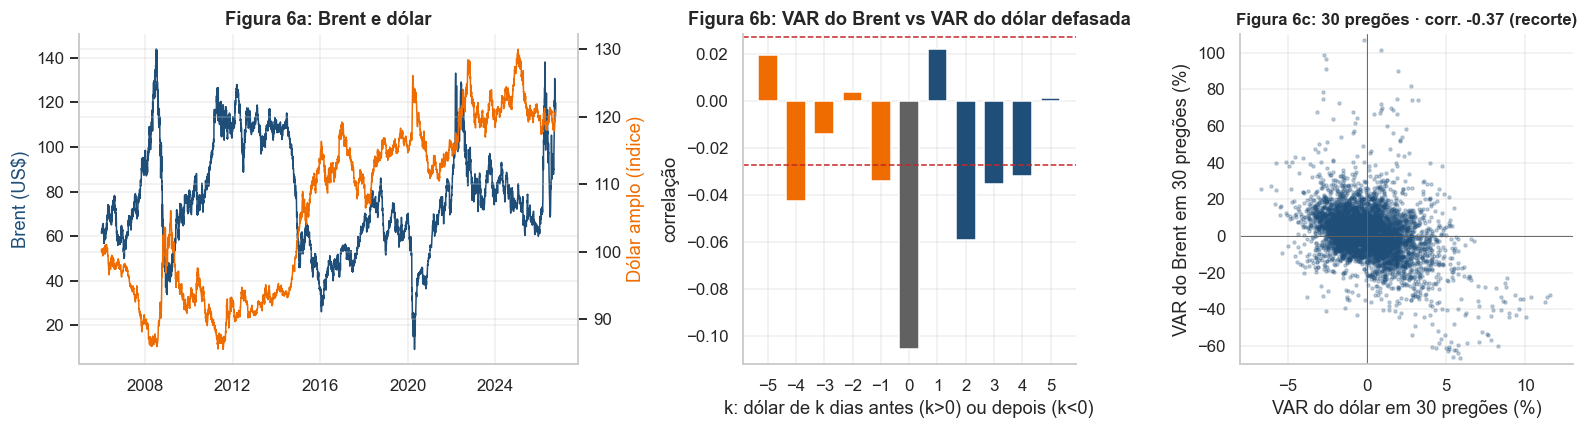

Em 30 pregões: correlação -0.37 (tudo) | -0.25 (sem 2008-09 e 2020) | -0.27 (só 2019 em diante). Janelas sobrepostas: o número vale como descrição, não como teste.
Correlação no mesmo dia: Pearson -0.106 | Spearman -0.118  (limite de ruído ±0.027, n = 5144)
Correlação com o dólar de k dias antes: {1: 0.022, 2: -0.059, 3: -0.035, 4: -0.032, 5: 0.002}


In [12]:
# 3.1 Alinhamento por data (relação contemporânea): usa a série bruta do dólar, mesma data do Brent
duas = df[["data", "preco_usd"]].merge(dolar.rename(columns={"dolar_amplo": "dolar"}), on="data", how="inner").set_index("data")
duas["VAR_B"] = duas["preco_usd"].pct_change() * 100
duas["VAR_D"] = duas["dolar"].pct_change() * 100
duas = duas.dropna()
c_dia = duas["VAR_B"].corr(duas["VAR_D"])
c_dia_sp = duas["VAR_B"].corr(duas["VAR_D"], method="spearman")

# correlação defasada: VAR do Brent hoje vs VAR do dólar k dias ANTES (k > 0 = dólar mexe primeiro)
lags = list(range(-5, 6))
cl = [duas["VAR_B"].corr(duas["VAR_D"].shift(k)) for k in lags]
n = len(duas); ic = 1.96 / np.sqrt(n)

# VAR de 30 pregões: nível de "tendência" (janelas sobrepostas, apenas ilustrativo)
duas["VAR_B30"] = (duas["preco_usd"] / duas["preco_usd"].shift(30) - 1) * 100
duas["VAR_D30"] = (duas["dolar"] / duas["dolar"].shift(30) - 1) * 100
c_30 = duas["VAR_B30"].corr(duas["VAR_D30"])

fig, axs = plt.subplots(1, 3, figsize=(14.5, 4.0), gridspec_kw={"width_ratios": [1.5, 1, 1]})
a1 = axs[0]; a1b = a1.twinx()
a1.plot(duas.index, duas["preco_usd"], color=AZUL, lw=1.0); a1b.plot(duas.index, duas["dolar"], color=LARANJA, lw=1.0)
a1.set_ylabel("Brent (US$)", color=AZUL); a1b.set_ylabel("Dólar amplo (índice)", color=LARANJA); a1b.spines["right"].set_visible(True)
a1.set_title("Figura 6a: Brent e dólar")
axs[1].bar(lags, cl, color=[AZUL if k > 0 else (CINZA if k == 0 else LARANJA) for k in lags], width=0.7)
axs[1].axhline(ic, color=VERMELHO, ls="--", lw=1); axs[1].axhline(-ic, color=VERMELHO, ls="--", lw=1)
axs[1].set_xticks(lags); axs[1].set_xlabel("k: dólar de k dias antes (k>0) ou depois (k<0)"); axs[1].set_ylabel("correlação")
axs[1].set_title("Figura 6b: VAR do Brent vs VAR do dólar defasada")
axs[2].scatter(duas["VAR_D30"], duas["VAR_B30"], s=4, alpha=0.25, color=AZUL)
axs[2].axhline(0, color=CINZA, lw=0.6); axs[2].axvline(0, color=CINZA, lw=0.6)
axs[2].set_xlim(-8, 13); axs[2].set_ylim(-70, 110)
axs[2].set_xlabel("VAR do dólar em 30 pregões (%)"); axs[2].set_ylabel("VAR do Brent em 30 pregões (%)")
axs[2].set_title(f"Figura 6c: 30 pregões · corr. {c_30:+.2f} (recorte)", fontsize=11)
plt.tight_layout(); plt.show()
ext = ((duas.index >= "2008-06-01") & (duas.index <= "2009-12-31")) | ((duas.index >= "2020-02-01") & (duas.index <= "2020-12-31"))
c30_sem_ext = duas.loc[~ext, ["VAR_B30", "VAR_D30"]].dropna().corr().iloc[0, 1]
c30_2019 = duas.loc[duas.index >= "2019-01-01", ["VAR_B30", "VAR_D30"]].dropna().corr().iloc[0, 1]
print(f"Em 30 pregões: correlação {c_30:+.2f} (tudo) | {c30_sem_ext:+.2f} (sem 2008-09 e 2020) | {c30_2019:+.2f} (só 2019 em diante). Janelas sobrepostas: o número vale como descrição, não como teste.")
print(f"Correlação no mesmo dia: Pearson {c_dia:+.3f} | Spearman {c_dia_sp:+.3f}  (limite de ruído ±{ic:.3f}, n = {n})")
print("Correlação com o dólar de k dias antes:", {k: round(float(v), 3) for k, v in zip(lags, cl) if k > 0})

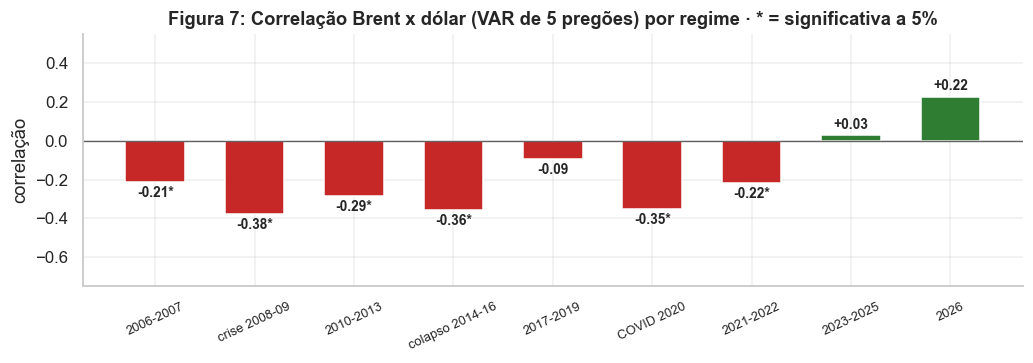

Período,Semanas,Correlação,p-valor
2006-2007,102,-0.21,0.032
crise 2008-09,102,-0.38,0.000
2010-2013,198,-0.29,0.000
colapso 2014-16,149,-0.36,0.000
2017-2019,148,-0.09,0.257
COVID 2020,48,-0.35,0.015
2021-2022,99,-0.22,0.029
2023-2025,146,+0.03,0.745
2026,36,+0.22,0.188


In [13]:
# 3.1b A relação com o dólar é estável? correlação da VAR de 5 pregões (janelas sem sobreposição) por regime histórico
PERIODOS = [("2006-2007", "2006-01-01", "2007-12-31"), ("crise 2008-09", "2008-01-01", "2009-12-31"), ("2010-2013", "2010-01-01", "2013-12-31"),
            ("colapso 2014-16", "2014-01-01", "2016-12-31"), ("2017-2019", "2017-01-01", "2019-12-31"), ("COVID 2020", "2020-01-01", "2020-12-31"),
            ("2021-2022", "2021-01-01", "2022-12-31"), ("2023-2025", "2023-01-01", "2025-12-31"), ("2026", "2026-01-01", "2026-12-31")]
sem = duas[["preco_usd", "dolar"]].iloc[::5].pct_change().dropna() * 100       # VAR de 5 pregões, sem sobreposição
linhas = []
for nome, i0, i1 in PERIODOS:
    s = sem.loc[i0:i1]
    c, p = stats.pearsonr(s["preco_usd"], s["dolar"]) if len(s) > 8 else (np.nan, np.nan)
    linhas.append({"Período": nome, "Semanas": len(s), "Correlação": c, "p-valor": p})
CORR_REG = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(9.5, 3.4))
cores = [VERMELHO if v < 0 else VERDE for v in CORR_REG["Correlação"]]
barras = ax.bar(CORR_REG["Período"], CORR_REG["Correlação"], color=cores, width=0.6)
for b, v, p in zip(barras, CORR_REG["Correlação"], CORR_REG["p-valor"]):
    ax.text(b.get_x() + b.get_width()/2, v + (0.02 if v >= 0 else -0.02), f"{v:+.2f}{'*' if p < 0.05 else ''}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9, fontweight="bold")
ax.axhline(0, color=CINZA, lw=0.9); ax.set_ylim(-0.75, 0.55)
ax.set_title("Figura 7: Correlação Brent x dólar (VAR de 5 pregões) por regime · * = significativa a 5%")
ax.tick_params(axis="x", rotation=25, labelsize=8.5); ax.set_ylabel("correlação")
plt.tight_layout(); plt.show()
display(CORR_REG.style.hide(axis="index").format({"Correlação": "{:+.2f}", "p-valor": "{:.3f}"}))

### 3.2 O que o dólar diz

**1. Existe uma relação inversa (dólar sobe, Brent cai), forte no longo prazo e fraca no curto.**
- No mesmo dia a correlação das variações é **−0,11** (ruído esperado: ±0,03).
- Em 30 pregões a correlação é **−0,37**. Tirando 2008-09 e 2020, continua em **−0,25**, e só de 2019 em diante é **−0,27**. É a escala em que o vínculo aparece. (Janelas de 30 dias se sobrepõem, então o número descreve, mas não prova.)

**2. No curto prazo (semanal) o vínculo não é estável: foi forte até 2016 e depois oscilou.**
- De 2006 a 2016 e em 2020, a correlação de 5 pregões foi negativa e significativa (**−0,21 a −0,38**).
- Em **2017-2019 foi −0,09 (não significativa)**, em 2021-22 voltou a **−0,22 (significativa)**, em **2023-2025 foi +0,03** e em **2026 foi +0,22 (não significativa)**.
- Hipótese (não testada aqui): em crises de demanda e crédito global (2008, 2014-16, COVID) dólar e petróleo andam em sentidos opostos; em choques de oferta (2026) o vínculo se perde.

**3. O dólar de ontem quase não antecipa o Brent de hoje.** As correlações com o dólar de 1 a 5 dias antes ficam entre −0,06 e +0,02, no nível do ruído.

**Para a modelagem:** o dólar é uma variável **de contexto**, útil para a tendência de semanas (médias e variações de 7 e 30 dias), mas não um motor da previsão diária. Entra defasado (D-1). O ganho esperado é pequeno e instável entre regimes, e o SHAP e a ablação decidem se ele fica. *Ressalva: o defeito de datas do Ipeadata em 2006-2018 pode enfraquecer as correlações curtas medidas nesse período.*

### 3.3 Brent e estoques de petróleo dos EUA

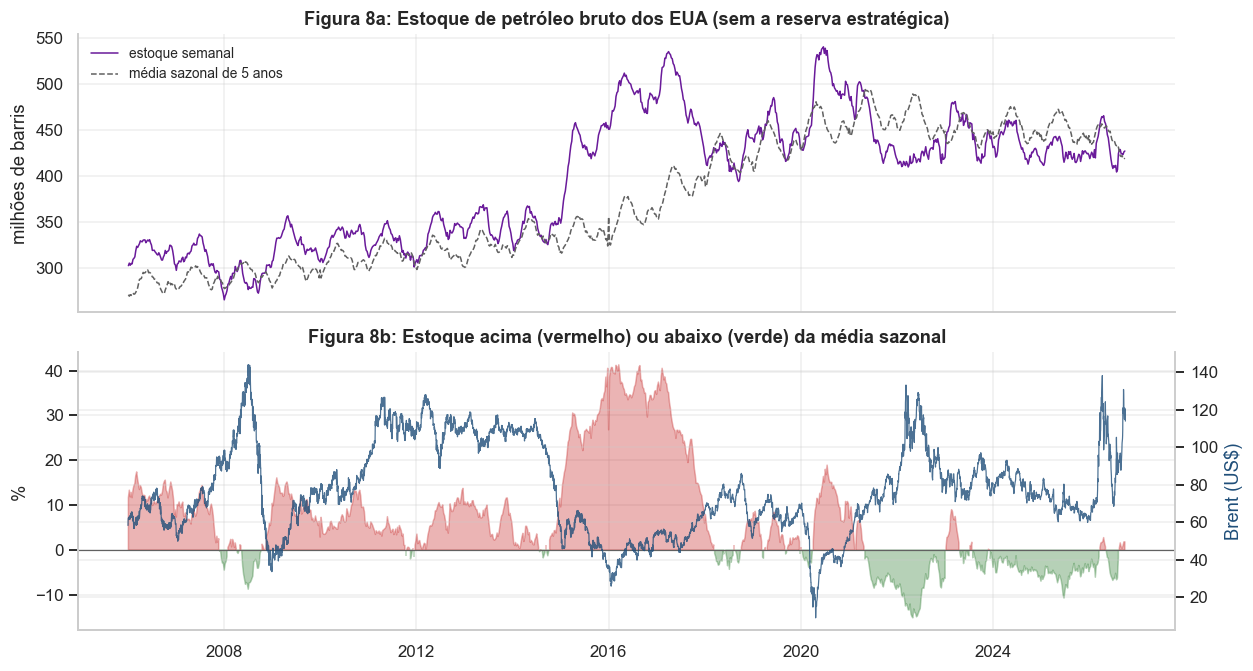

Estoque hoje: 427,3 milhões de barris, +1.9% vs média sazonal de 5 anos


In [14]:
# 3.3 Estoque vs média sazonal de 5 anos (mesma semana do ano) — sem olhar o futuro
e = est.copy()
e["sem_ano"] = e["semana_ref"].dt.isocalendar().week.astype(int).clip(upper=52)
e["ano"] = e["semana_ref"].dt.year
def media_5a(linha):
    h = e[(e["sem_ano"] == linha["sem_ano"]) & (e["ano"] < linha["ano"]) & (e["ano"] >= linha["ano"] - 5)]
    return h["estoque_mil_barris"].mean() if len(h) >= 3 else np.nan
e["media_5a"] = e.apply(media_5a, axis=1)
e["desvio_abs"] = e["estoque_mil_barris"] - e["media_5a"]
e["desvio_pct"] = e["desvio_abs"] / e["media_5a"] * 100
e["VAR_1S"] = e["estoque_mil_barris"].pct_change() * 100
e = e[e["semana_ref"] >= "2006-01-01"].reset_index(drop=True)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11.5, 6.2), sharex=True)
a1.plot(e["semana_ref"], e["estoque_mil_barris"] / 1000, color=ROXO, lw=1.0, label="estoque semanal")
a1.plot(e["semana_ref"], e["media_5a"] / 1000, color=CINZA, lw=1.0, ls="--", label="média sazonal de 5 anos")
a1.set_ylabel("milhões de barris"); a1.set_title("Figura 8a: Estoque de petróleo bruto dos EUA (sem a reserva estratégica)")
a1.legend(frameon=False, fontsize=9, loc="upper left")
a2.fill_between(e["semana_ref"], e["desvio_pct"], 0, where=e["desvio_pct"] > 0, color=VERMELHO, alpha=0.35)
a2.fill_between(e["semana_ref"], e["desvio_pct"], 0, where=e["desvio_pct"] <= 0, color=VERDE, alpha=0.35)
a2.axhline(0, color=CINZA, lw=0.8)
a2.set_ylabel("%"); a2.set_title("Figura 8b: Estoque acima (vermelho) ou abaixo (verde) da média sazonal")
a2b = a2.twinx(); a2b.plot(D, y, color=AZUL, lw=0.8, alpha=0.8); a2b.set_ylabel("Brent (US$)", color=AZUL); a2b.spines["right"].set_visible(True)
plt.tight_layout(); plt.show()
print(f"Estoque hoje: {pt(e['estoque_mil_barris'].iloc[-1]/1000, 1)} milhões de barris, {e['desvio_pct'].iloc[-1]:+.1f}% vs média sazonal de 5 anos")

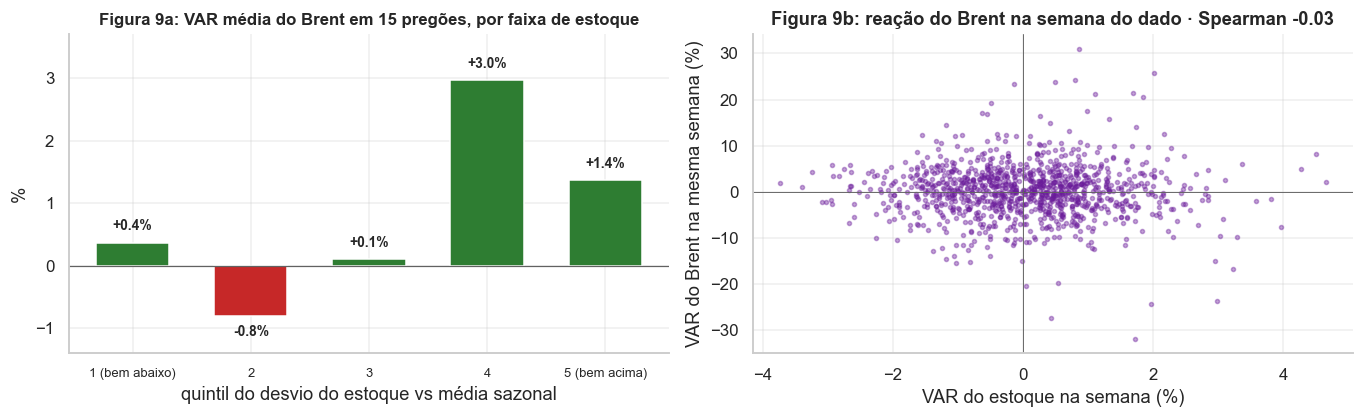

,Semanas,Desvio médio (%),VAR 15 pregões média (%),VAR 15 pregões mediana (%),% das vezes com alta
faixa,,,,,
1 (bem abaixo),216,-6.19,0.37,-0.44,49.07
2,215,-0.47,-0.80,0.06,50.70
3,216,4.51,0.11,0.74,52.78
4,215,9.67,2.97,2.20,60.47
5 (bem acima),216,25.57,1.36,1.29,56.48


Desvio sazonal do estoque x VAR do Brent nos 15 pregões seguintes: Spearman +0.082 (p = 0.007); sem sobreposição: +0.092 (p = 0.081), n = 360
VAR semanal do estoque x VAR do Brent nos 15 pregões seguintes: Spearman +0.005 (p = 0.863)
VAR semanal do estoque x VAR do Brent na MESMA semana: Spearman -0.031 (p = 0.317)


In [15]:
# 3.4 O estoque ajuda a prever o Brent? VAR dos 15 pregões seguintes à divulgação, por faixa de desvio sazonal
d_est = df[["data", "preco_usd", "VAR_15D_FUT"]].sort_values("data")
e2 = e.dropna(subset=["desvio_pct"]).copy()
e2 = pd.merge_asof(e2.sort_values("data_disponivel"), d_est.rename(columns={"data": "d_div"}), left_on="data_disponivel", right_on="d_div", direction="forward").dropna(subset=["VAR_15D_FUT"])
# reação na própria semana: Brent da sexta de referência até a divulgação (já aconteceu quando o dado sai)
p_ref = pd.merge_asof(e2.sort_values("semana_ref")[["semana_ref"]], d_est.rename(columns={"data": "d_ref", "preco_usd": "p_ref"})[["d_ref", "p_ref"]], left_on="semana_ref", right_on="d_ref", direction="backward")
e2 = e2.sort_values("semana_ref").reset_index(drop=True); e2["p_ref"] = p_ref["p_ref"].values
e2["VAR_semana_atual"] = (e2["preco_usd"] / e2["p_ref"] - 1) * 100

e2["faixa"] = pd.qcut(e2["desvio_pct"], 5, labels=["1 (bem abaixo)", "2", "3", "4", "5 (bem acima)"])
tb = e2.groupby("faixa", observed=True).agg(semanas=("desvio_pct", "size"), desvio_medio=("desvio_pct", "mean"),
                                            VAR15_media=("VAR_15D_FUT", "mean"), VAR15_mediana=("VAR_15D_FUT", "median"),
                                            positivo=("VAR_15D_FUT", lambda s: (s > 0).mean() * 100))
rho, p_rho = stats.spearmanr(e2["desvio_pct"], e2["VAR_15D_FUT"])
sub = e2.iloc[::3]                                   # a cada 3 semanas: janelas de 15 pregões não se sobrepõem
rho_s, p_rho_s = stats.spearmanr(sub["desvio_pct"], sub["VAR_15D_FUT"])
rho_w, p_rho_w = stats.spearmanr(e2["VAR_1S"].fillna(0), e2["VAR_15D_FUT"])
rho_c, p_rho_c = stats.spearmanr(e2["VAR_1S"].fillna(0), e2["VAR_semana_atual"])

fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.9))
axs[0].bar(range(5), tb["VAR15_media"], color=[VERDE if v > 0 else VERMELHO for v in tb["VAR15_media"]], width=0.62)
axs[0].set_xticks(range(5)); axs[0].set_xticklabels(tb.index, fontsize=8.5); axs[0].axhline(0, color=CINZA, lw=0.8)
for i, v in enumerate(tb["VAR15_media"]): axs[0].text(i, v + (0.15 if v >= 0 else -0.15), f"{v:+.1f}%", ha="center", va="bottom" if v >= 0 else "top", fontweight="bold", fontsize=9)
axs[0].set_ylim(-1.4, 3.7); axs[0].set_title("Figura 9a: VAR média do Brent em 15 pregões, por faixa de estoque", fontsize=11)
axs[0].set_xlabel("quintil do desvio do estoque vs média sazonal"); axs[0].set_ylabel("%")
axs[1].scatter(e2["VAR_1S"], e2["VAR_semana_atual"], s=7, alpha=0.4, color=ROXO)
axs[1].axhline(0, color=CINZA, lw=0.6); axs[1].axvline(0, color=CINZA, lw=0.6)
axs[1].set_xlabel("VAR do estoque na semana (%)"); axs[1].set_ylabel("VAR do Brent na mesma semana (%)")
axs[1].set_title(f"Figura 9b: reação do Brent na semana do dado · Spearman {rho_c:+.2f}")
plt.tight_layout(); plt.show()
display(tb.rename(columns={"semanas": "Semanas", "desvio_medio": "Desvio médio (%)", "VAR15_media": "VAR 15 pregões média (%)",
                           "VAR15_mediana": "VAR 15 pregões mediana (%)", "positivo": "% das vezes com alta"}).round(2))
print(f"Desvio sazonal do estoque x VAR do Brent nos 15 pregões seguintes: Spearman {rho:+.3f} (p = {p_rho:.3f}); sem sobreposição: {rho_s:+.3f} (p = {p_rho_s:.3f}), n = {len(sub)}")
print(f"VAR semanal do estoque x VAR do Brent nos 15 pregões seguintes: Spearman {rho_w:+.3f} (p = {p_rho_w:.3f})")
print(f"VAR semanal do estoque x VAR do Brent na MESMA semana: Spearman {rho_c:+.3f} (p = {p_rho_c:.3f})")

### 3.5 O que os estoques dizem

**1. O nível de estoque sozinho conta pouco.** Os estoques dos EUA subiram bastante ao longo do período (de ~300 para ~430 milhões de barris) e tiveram dois grandes períodos acima da média sazonal: **2015-2017** (até +40%, em pleno colapso do preço) e **2020-21**. Hoje estão em 427,3 milhões, **+1,9% acima da média sazonal de 5 anos**, praticamente em linha.

**2. A relação com o preço futuro é fraca e tem sinal contraintuitivo.** Por quintil de desvio do estoque, a VAR média do Brent nos 15 pregões seguintes é **+0,4%, −0,8%, +0,1%, +3,0% e +1,4%**: sem ordem lógica. A correlação (Spearman +0,08, p = 0,007; sem sobreposição +0,09, p = 0,08, n = 360) tem sinal oposto ao da teoria (mais estoque deveria pressionar o preço). Provavelmente é efeito de ciclo, não causa.

**3. O mercado não reage de forma mensurável ao dado semanal.** A variação semanal do estoque tem correlação de **−0,03** (não significativa) com a variação do Brent na mesma semana e de +0,00 com os 15 pregões seguintes. O dado semanal é público e já "precificado" quando sai.

**Para a modelagem:** estoques entram como **contexto** (desvio sazonal) e não como motor da previsão. Não esperamos ganho relevante sobre o baseline. Se o SHAP mostrar peso, vale desconfiar de relação espúria.

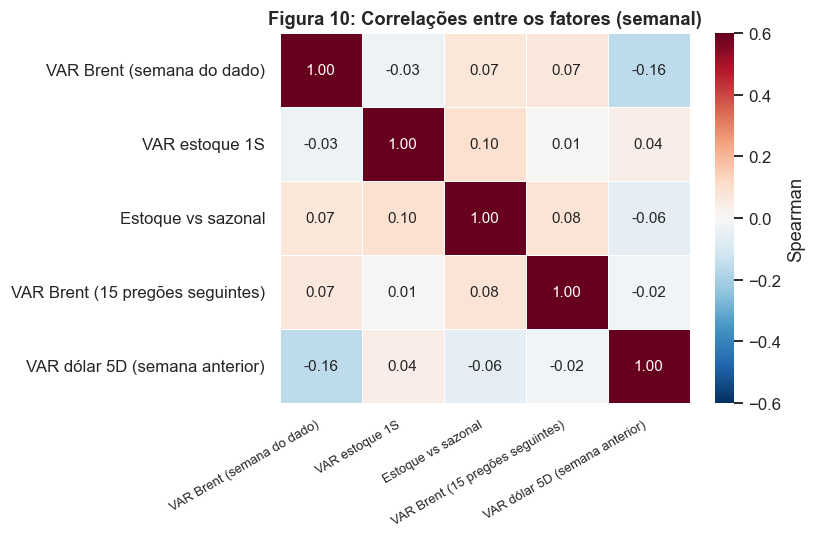

In [16]:
# 3.6 Mapa de correlações entre os fatores (frequência semanal, sem sobreposição)
sm = e2[["VAR_semana_atual", "VAR_1S", "desvio_pct", "VAR_15D_FUT"]].copy()
sm["VAR_dolar_5D"] = np.nan
dsem = dolar.set_index("data")["dolar_amplo"]
sm["VAR_dolar_5D"] = [ (dsem.asof(d1) / dsem.asof(d0) - 1) * 100 for d0, d1 in zip(e2["semana_ref"] - pd.Timedelta(days=7), e2["semana_ref"]) ]
sm = sm.rename(columns={"VAR_semana_atual": "VAR Brent (semana do dado)", "VAR_1S": "VAR estoque 1S", "desvio_pct": "Estoque vs sazonal",
                        "VAR_15D_FUT": "VAR Brent (15 pregões seguintes)", "VAR_dolar_5D": "VAR dólar 5D (semana anterior)"})
fig, ax = plt.subplots(figsize=(7.4, 5.0))
sns.heatmap(sm.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, linewidths=0.5, linecolor="white", ax=ax, cbar_kws={"label": "Spearman"})
ax.set_title("Figura 10: Correlações entre os fatores (semanal)"); ax.tick_params(axis="x", rotation=30, labelsize=8.5)
plt.setp(ax.get_xticklabels(), ha="right"); plt.tight_layout(); plt.show()

## Bloco 4. Padrões: tendência, sazonalidade de calendário e memória

Decidimos na Fase 1 se as **features de calendário** (mês, trimestre, semana do ano, dia da semana) têm base empírica, e como a série "lembra" do passado.

### 4.1 Decomposição em tendência e sazonalidade (STL)

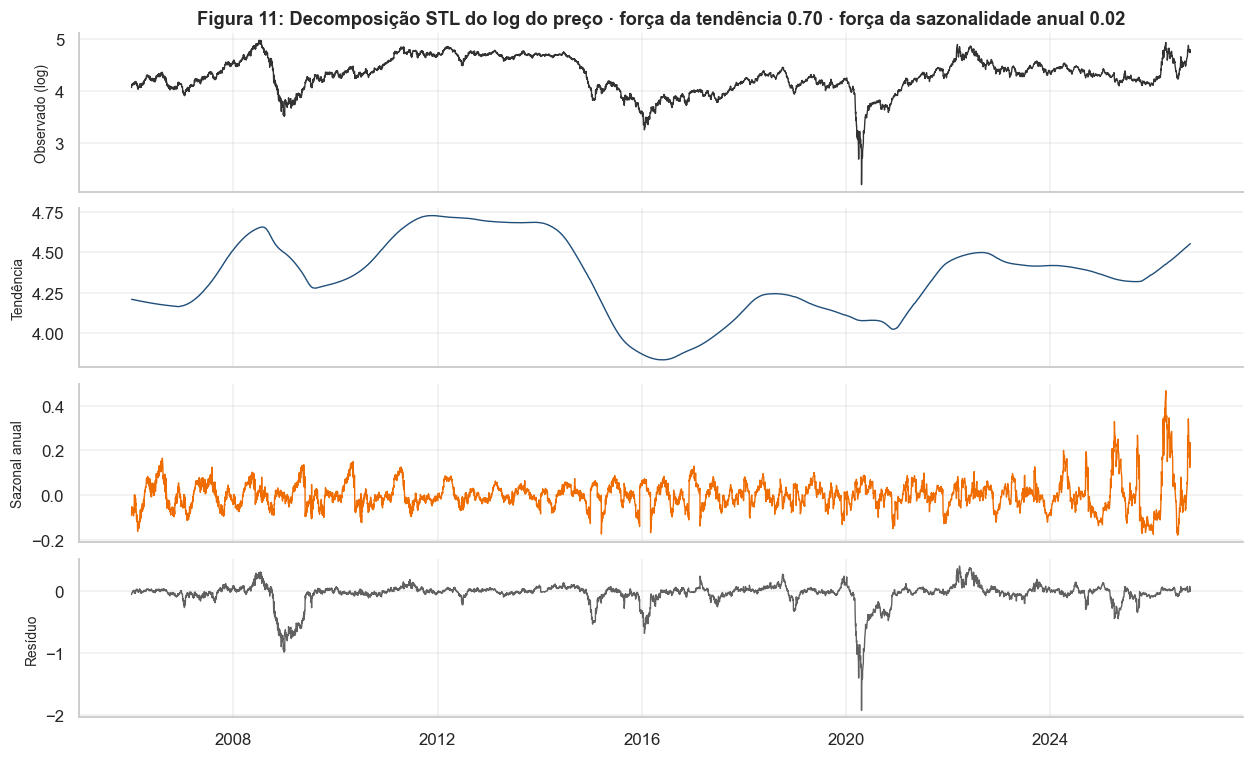

Força da tendência: 0.696 | Força da sazonalidade anual: 0.023 (0 = nenhuma, 1 = total)
DESV_PAD do componente sazonal: 6.3 p.p. (log) | da tendência: 24.0 p.p. | do resíduo: 18.2 p.p.


In [17]:
# 4.1 STL do log-preço: ciclo anual (252 pregões)
lp = pd.Series(np.log(y), index=D)
stl = STL(lp, period=252, robust=True).fit()
vr, vt, vs = stl.resid.var(), stl.trend.var(), stl.seasonal.var()
forca_tend = max(0, 1 - vr / (vt + vr)) if False else max(0, 1 - vr / np.var(stl.trend + stl.resid))
forca_saz  = max(0, 1 - vr / np.var(stl.seasonal + stl.resid))

fig, eixos = plt.subplots(4, 1, figsize=(11.5, 7.0), sharex=True)
for eixo, (nome, serie, cor) in zip(eixos, [("Observado (log)", stl.observed, "#333333"), ("Tendência", stl.trend, AZUL), ("Sazonal anual", stl.seasonal, LARANJA), ("Resíduo", stl.resid, CINZA)]):
    eixo.plot(serie.index, serie.values, lw=0.9, color=cor); eixo.set_ylabel(nome, fontsize=9)
eixos[0].set_title(f"Figura 11: Decomposição STL do log do preço · força da tendência {forca_tend:.2f} · força da sazonalidade anual {forca_saz:.2f}")
plt.tight_layout(); plt.show()
print(f"Força da tendência: {forca_tend:.3f} | Força da sazonalidade anual: {forca_saz:.3f} (0 = nenhuma, 1 = total)")
print(f"DESV_PAD do componente sazonal: {stl.seasonal.std()*100:.1f} p.p. (log) | da tendência: {stl.trend.std()*100:.1f} p.p. | do resíduo: {stl.resid.std()*100:.1f} p.p.")

### 4.2 Existe efeito de calendário? Mês, trimestre, dia da semana

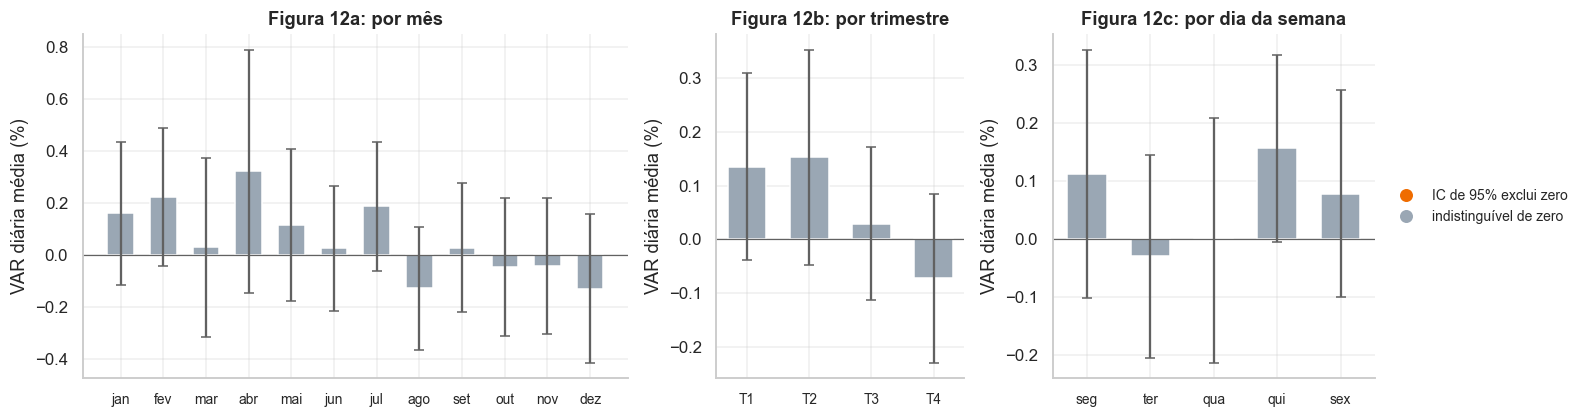

Calendário,Categorias,Kruskal-Wallis p,Repete nas duas metades (Spearman),p da repetição
mês,12,0.248,+0.29,0.366
trimestre,4,0.082,+0.40,0.600
dia da semana,5,0.401,-0.30,0.624
semana do ano,52,0.852,-0.07,0.635


Divisão das metades em 15/04/2016
Semanas do ano com efeito 'significativo': 1 de 52 (esperado só por acaso: ~2.6)


In [18]:
# 4.2 VAR diária média por mês, trimestre e dia da semana, com intervalo de confiança de 95%
cal = df.dropna(subset=["VAR_1D"]).copy()
cal["mes"], cal["trimestre"], cal["dia_semana"] = cal["data"].dt.month, cal["data"].dt.quarter, cal["data"].dt.dayofweek
cal["semana_ano"] = cal["data"].dt.isocalendar().week.astype(int).clip(upper=52)
NOMES = {"mes": ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"],
         "trimestre": ["T1", "T2", "T3", "T4"], "dia_semana": ["seg", "ter", "qua", "qui", "sex"]}

def efeito(col):
    g = cal.groupby(col)["VAR_1D"].agg(["mean", "std", "count"])
    g["ic"] = 1.96 * g["std"] / np.sqrt(g["count"])
    return g

fig, axs = plt.subplots(1, 3, figsize=(14.5, 3.9), gridspec_kw={"width_ratios": [2.2, 1, 1.3]})
for ax, col, titulo in zip(axs, ["mes", "trimestre", "dia_semana"], ["Figura 12a: por mês", "Figura 12b: por trimestre", "Figura 12c: por dia da semana"]):
    g = efeito(col)
    sig = (g["mean"] - g["ic"] > 0) | (g["mean"] + g["ic"] < 0)
    ax.bar(range(len(g)), g["mean"], yerr=g["ic"], capsize=3, width=0.62,
           color=[LARANJA if s else "#9aa7b4" for s in sig], ecolor=CINZA)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(NOMES[col], fontsize=9); ax.axhline(0, color=CINZA, lw=0.8)
    ax.set_title(titulo); ax.set_ylabel("VAR diária média (%)")
legenda_lateral(axs[2], [bolinha(LARANJA, "IC de 95% exclui zero"), bolinha("#9aa7b4", "indistinguível de zero")])
plt.tight_layout(); plt.show()

# testes: o efeito existe (Kruskal-Wallis) e se repete fora da amostra (1ª metade x 2ª metade)?
meio = cal["data"].quantile(0.5, interpolation="nearest")
linhas = []
for col, rot in [("mes", "mês"), ("trimestre", "trimestre"), ("dia_semana", "dia da semana"), ("semana_ano", "semana do ano")]:
    grupos = [g["VAR_1D"].values for _, g in cal.groupby(col)]
    h, p = stats.kruskal(*grupos)
    m1 = cal[cal["data"] <= meio].groupby(col)["VAR_1D"].mean(); m2 = cal[cal["data"] > meio].groupby(col)["VAR_1D"].mean()
    rho_c2, p_c2 = stats.spearmanr(m1, m2)
    linhas.append({"Calendário": rot, "Categorias": cal[col].nunique(), "Kruskal-Wallis p": p, "Repete nas duas metades (Spearman)": rho_c2, "p da repetição": p_c2})
TESTE_CAL = pd.DataFrame(linhas)
display(TESTE_CAL.style.hide(axis="index").format({"Kruskal-Wallis p": "{:.3f}", "Repete nas duas metades (Spearman)": "{:+.2f}", "p da repetição": "{:.3f}"}))
print(f"Divisão das metades em {meio:%d/%m/%Y}")

# semana do ano: quantas das 52 semanas têm IC excluindo zero, contra os ~5% esperados só por acaso
gw = efeito("semana_ano"); sig_w = ((gw["mean"] - gw["ic"] > 0) | (gw["mean"] + gw["ic"] < 0)).sum()
print(f"Semanas do ano com efeito 'significativo': {sig_w} de 52 (esperado só por acaso: ~{0.05*52:.1f})")

#### O que o calendário diz

**Nenhum efeito de calendário se distingue de zero na VAR diária.**
- Nos gráficos, todos os intervalos de confiança de 95% (mês, trimestre, dia da semana) incluem zero.
- Nos testes, o p-valor de Kruskal-Wallis é 0,25 (mês), 0,08 (trimestre), 0,40 (dia da semana) e 0,85 (semana do ano). Nenhum passa de 5%.
- Das 52 semanas do ano, **1** tem efeito "significativo", contra ~2,6 esperadas só por acaso.
- Os padrões **não se repetem** entre a primeira e a segunda metade do período (correlação entre metades sem significância estatística).
- A decomposição STL confirma: **força sazonal anual de 0,02**, contra 0,70 de tendência.

**Para a modelagem:** a base empírica para as features de calendário é **fraca**. Elas entram, como combinado, mas esperamos que o SHAP e a ablação mostrem pouco ou nenhum ganho. Se não agregarem, ficam registradas como "testadas e descartadas". *Ressalva: o efeito de dia da semana também sofre com o defeito de datas do Ipeadata em 2006-2018.*

### 4.3 Memória da série

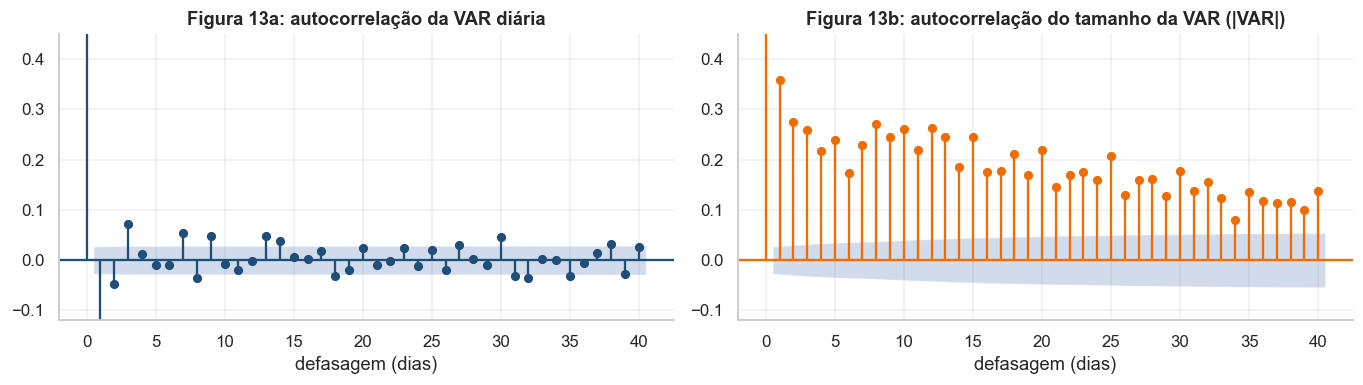

Só 2019 a 2026 (período sem o defeito de datas): autocorrelação da VAR em 1 dia -0.025; de |VAR| em 1, 5 e 20 dias: 0.40, 0.28, 0.22
Autocorrelação da VAR diária em 1 dia: -0.199 (limite de ruído ±0.027)
Autocorrelação de |VAR| em 1, 5 e 20 dias: 0.36, 0.24, 0.22


In [19]:
# 4.3 Autocorrelação: o preço de ontem prevê a variação de hoje? E a instabilidade, é persistente?
r = df["VAR_1D"].dropna()
fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.6))
plot_acf(r, lags=40, ax=axs[0], color=AZUL, vlines_kwargs={"colors": AZUL}); axs[0].set_title("Figura 13a: autocorrelação da VAR diária")
plot_acf(r.abs(), lags=40, ax=axs[1], color=LARANJA, vlines_kwargs={"colors": LARANJA}); axs[1].set_title("Figura 13b: autocorrelação do tamanho da VAR (|VAR|)")
for a in axs: a.set_xlabel("defasagem (dias)"); a.set_ylim(-0.12, 0.45)
plt.tight_layout(); plt.show()
ac1 = r.autocorr(1); ac_abs = [r.abs().autocorr(k) for k in (1, 5, 20)]
rl = df.loc[df["data"] >= "2019-01-01", "VAR_1D"].dropna()
print(f"Só 2019 a 2026 (período sem o defeito de datas): autocorrelação da VAR em 1 dia {rl.autocorr(1):+.3f}; de |VAR| em 1, 5 e 20 dias: {rl.abs().autocorr(1):.2f}, {rl.abs().autocorr(5):.2f}, {rl.abs().autocorr(20):.2f}")
print(f"Autocorrelação da VAR diária em 1 dia: {ac1:+.3f} (limite de ruído ±{1.96/np.sqrt(len(r)):.3f})")
print(f"Autocorrelação de |VAR| em 1, 5 e 20 dias: {ac_abs[0]:.2f}, {ac_abs[1]:.2f}, {ac_abs[2]:.2f}")

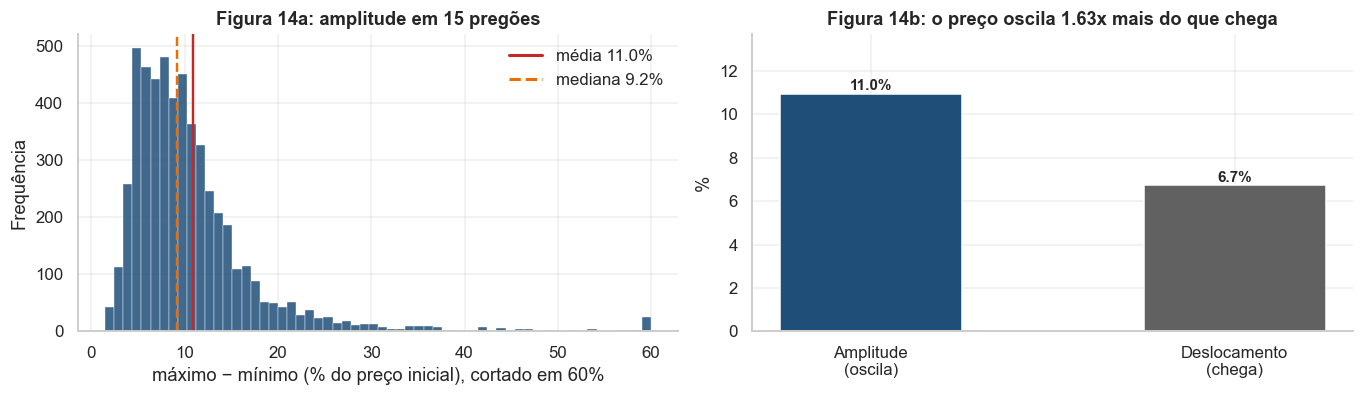

Amplitude média em 15 pregões: 11.0% (mediana 9.2%) | deslocamento médio 6.7% | razão 1.63x
Em 15 pregões o preço sobe em 53.4% das vezes (cai em 46.6%)
|VAR| em 15 pregões: média 6.7%, mediana 5.0%, p90 13.6%


In [20]:
# 4.4 Quanto o preço OSCILA em 15 pregões contra quanto ele realmente DESLOCA
amplitude    = np.array([(y[t:t+H].max() - y[t:t+H].min()) / y[t] * 100 for t in range(len(y) - H)])
deslocamento = np.array([abs(y[t+H-1] / y[t] - 1) * 100 for t in range(len(y) - H)])
direcao_h = np.array([y[t+H-1] > y[t] for t in range(len(y) - H)])
razao = np.mean(amplitude) / np.mean(deslocamento)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 3.7))
a1.hist(np.clip(amplitude, 0, 60), bins=60, color=AZUL, alpha=0.85, edgecolor="white", linewidth=0.3)
a1.axvline(np.mean(amplitude), color=VERMELHO, lw=1.6); a1.axvline(np.median(amplitude), color=LARANJA, lw=1.6, ls="--")
a1.set_title("Figura 14a: amplitude em 15 pregões"); a1.set_xlabel("máximo − mínimo (% do preço inicial), cortado em 60%"); a1.set_ylabel("Frequência")
a1.legend(handles=[Line2D([], [], color=VERMELHO, lw=2, label=f"média {np.mean(amplitude):.1f}%"), Line2D([], [], color=LARANJA, lw=2, ls="--", label=f"mediana {np.median(amplitude):.1f}%")], frameon=False)
barras = a2.bar(["Amplitude\n(oscila)", "Deslocamento\n(chega)"], [np.mean(amplitude), np.mean(deslocamento)], color=[AZUL, CINZA], width=0.5)
for b, v in zip(barras, [np.mean(amplitude), np.mean(deslocamento)]):
    a2.text(b.get_x() + b.get_width()/2, v + 0.15, f"{v:.1f}%", ha="center", fontweight="bold")
a2.set_ylim(0, np.mean(amplitude) * 1.25); a2.set_ylabel("%"); a2.set_title(f"Figura 14b: o preço oscila {razao:.2f}x mais do que chega")
plt.tight_layout(); plt.show()
print(f"Amplitude média em {H} pregões: {np.mean(amplitude):.1f}% (mediana {np.median(amplitude):.1f}%) | deslocamento médio {np.mean(deslocamento):.1f}% | razão {razao:.2f}x")
print(f"Em {H} pregões o preço sobe em {direcao_h.mean()*100:.1f}% das vezes (cai em {100-direcao_h.mean()*100:.1f}%)")
print(f"|VAR| em {H} pregões: média {np.mean(deslocamento):.1f}%, mediana {np.median(deslocamento):.1f}%, p90 {np.percentile(deslocamento, 90):.1f}%")

### 4.5 O que os padrões dizem

**1. A direção do dia não tem memória, mas o tamanho do movimento tem.**
- Em 2019-2026 (período sem o defeito de datas), a autocorrelação da VAR em 1 dia é **−0,03**: o movimento de hoje não ajuda a prever a direção de amanhã.
- A autocorrelação de |VAR| (o tamanho) é **0,40 em 1 dia, 0,28 em 5 e 0,22 em 20**: dias agitados vêm em sequência. É a mesma conclusão do regime de instabilidade (2.7).
- *Cuidado:* no período completo a autocorrelação em 1 dia dá **−0,20**, mas isso é um **artefato do defeito do Ipeadata** (em 2006-2018 a série do Ipeadata tem −0,34; a da EIA tem +0,02, tabela 1.5). Um modelo treinado nesses anos aprenderia uma "reversão à média diária" que não existe no mercado.

**2. Em 15 pregões o preço oscila mais do que chega.**
- A amplitude média (máximo menos mínimo) é de **11,0%** do preço inicial (mediana 9,2%), mas o deslocamento médio do início ao fim é de **6,7%**: razão de **1,63x**.
- O preço sobe em **53,4%** das janelas de 15 pregões: **quase um cara ou coroa**. Acertar a direção será difícil e não deve ser a promessa do modelo.
- O |VAR| em 15 pregões tem mediana de 5,0% e p90 de 13,6%.

**3. A tendência explica a maior parte da forma da série, e a sazonalidade anual quase nada.** Força da tendência 0,70; força sazonal 0,02.

## Bloco 5. Leitura para a modelagem

O que a EDA decide para as próximas fases:

| # | Achado | Decisão para a modelagem |
|---|---|---|
| 1 | O preço oscila em regimes; a instabilidade persiste (|VAR| autocorrelacionado) | A **faixa de incerteza deve depender do DESV_PAD 30D**, não ser fixa. Hoje o regime é instável |
| 2 | Em 15 pregões o preço sobe em 53% das vezes e oscila 1,6x mais do que chega | O modelo entrega **nível e faixa**, não aposta de direção. Comparar sempre com o baseline "amanhã = hoje" |
| 3 | Cauda gorda (curtose 32) | Calibrar a faixa **por backtest** (quantis dos erros), nunca por tabela normal |
| 4 | Dólar: relação inversa até 2016, ausente depois | Entra defasado (D-1) como contexto. Esperar ganho pequeno e instável |
| 5 | Estoques: fraco e com sinal contraintuitivo | Entra como desvio sazonal. Desconfiar de peso alto no SHAP |
| 6 | Calendário sem efeito distinguível de zero | Entra como combinado, mas a ablação provavelmente o descarta |
| 7 | Choques geopolíticos são imprevisíveis (Ormuz 2026) | Comunicar no app que a faixa não cobre eventos extremos |

### Decisão em aberto para a sua aprovação (portão da Fase 1): a janela de treino

A série do Ipeadata está **contaminada de 2006 a 2018** (tabela 1.5): ela fabrica reversão diária e instabilidade que o mercado não teve. De **2019 em diante** ela é equivalente à da EIA. Mantendo o Ipeadata como fonte, proponho tratar a **janela de treino como parte do protocolo de validação da Fase 2**, comparando:

- **(A) Treinar com 2019 a 2026** (~1.960 dias úteis): dados limpos, mas sem 2008 e 2014-16. Mantém os regimes extremos de 2020, 2022 e 2026.
- **(B) Treinar com 2006 a 2026** (~5.320 dias úteis): mais história, com o defeito.
- Em ambos, o teste (as janelas mais recentes) fica sempre no período limpo.
- Na Fase 4 repetimos o melhor modelo com a série da EIA como teste de sensibilidade.

**Pendências antes de citar na apresentação:** as datas dos eventos marcados como *conhecimento geral* (tabela 2.1) não foram checadas em fonte neste projeto.

---
# FASE 2. Features e protocolo de validação

## Bloco 6. Features e variável-alvo

### 6.1 O que o modelo recebe e o que ele prevê

O modelo roda **uma vez por dia (a origem `t`)** e prevê a variação do Brent daqui a `h` dias úteis, para `h` de 1 a 15. **Toda feature usa só informação disponível no fechamento de `t`.**

| Grupo | Features (25) |
|---|---|
| **Brent (8)** | preço em t, preço em t-7, VAR 1D, VAR 7D, VAR 30D, média 7D, média 30D, DESV_PAD 30D |
| **Dólar (6)** | nível (D-1), nível D-2, VAR 1D, VAR 7D, média 30D, DESV_PAD 30D |
| **Estoques EUA (7)** | nível, VAR 1S, VAR 4S, média 4S, média sazonal de 5 anos (mesma semana), desvio vs sazonal (absoluto e em %) |
| **Calendário (4)** | mês, trimestre, semana do ano, dia da semana |

Além dessas 25, criamos **4 candidatas cíclicas** (seno e cosseno do mês e da semana), fora do conjunto principal. Só entram se a ablação mostrar ganho.

**Alvo:** `VAR_h = 100 × ln(P[t+h] / P[t])`, a variação logarítmica (muito próxima da variação percentual em movimentos pequenos), para h = 1 … 15. O preço previsto é `P[t] × exp(VAR_h / 100)`.

**Quanto ao estoque:** a média sazonal usa só **anos anteriores** da mesma semana, e cada valor só vale a partir da data de divulgação (já garantido na base).

In [21]:
# 6.2 Construção das features (função única, reutilizável no app)
FEATURES_BRENT = ["brent_preco", "brent_preco_t7", "brent_var_1d", "brent_var_7d", "brent_var_30d",
                  "brent_media_7d", "brent_media_30d", "brent_desv_pad_30d"]
FEATURES_DOLAR = ["dolar_d1", "dolar_d2", "dolar_var_1d", "dolar_var_7d", "dolar_media_30d", "dolar_desv_pad_30d"]
FEATURES_EST   = ["est_nivel", "est_var_1s", "est_var_4s", "est_media_4s", "est_media_5a", "est_desvio_abs", "est_desvio_pct"]
FEATURES_CAL   = ["cal_mes", "cal_trimestre", "cal_semana_ano", "cal_dia_semana"]
FEATURES = FEATURES_BRENT + FEATURES_DOLAR + FEATURES_EST + FEATURES_CAL
CICLICAS = ["cal_mes_sin", "cal_mes_cos", "cal_semana_sin", "cal_semana_cos"]
GRUPO = {**{f: "Brent" for f in FEATURES_BRENT}, **{f: "Dólar" for f in FEATURES_DOLAR},
         **{f: "Estoques" for f in FEATURES_EST}, **{f: "Calendário" for f in FEATURES_CAL}}
assert len(FEATURES) == 25 and len(set(FEATURES)) == 25

def construir_features(base_d, est_w):
    """base_d: dias úteis do Brent com `dolar_d1`. est_w: estoque semanal. Cada linha usa apenas informação até a própria data."""
    d = base_d.sort_values("data").reset_index(drop=True)
    p = d["preco_usd"]; r = p.pct_change() * 100
    F = pd.DataFrame({"data": d["data"]})
    F["brent_preco"], F["brent_preco_t7"] = p, p.shift(7)
    F["brent_var_1d"], F["brent_var_7d"], F["brent_var_30d"] = r, p.pct_change(7) * 100, p.pct_change(30) * 100
    F["brent_media_7d"], F["brent_media_30d"] = p.rolling(7).mean(), p.rolling(30).mean()
    F["brent_desv_pad_30d"] = r.rolling(30).std()
    s = d["dolar_d1"]; rs = s.pct_change() * 100
    F["dolar_d1"], F["dolar_d2"] = s, s.shift(1)
    F["dolar_var_1d"], F["dolar_var_7d"] = rs, s.pct_change(7) * 100
    F["dolar_media_30d"], F["dolar_desv_pad_30d"] = s.rolling(30).mean(), rs.rolling(30).std()
    # estoques: calculados na frequência semanal e ligados ao dia pela data de divulgação
    e = est_w.sort_values("semana_ref").reset_index(drop=True).copy()
    e["sem"] = e["semana_ref"].dt.isocalendar().week.astype(int).clip(upper=52); e["ano"] = e["semana_ref"].dt.year
    u = e.drop_duplicates(["sem", "ano"], keep="last")[["sem", "ano", "estoque_mil_barris"]].sort_values(["sem", "ano"]).copy()
    u["media_5a"] = u.groupby("sem")["estoque_mil_barris"].transform(lambda x: x.shift(1).rolling(5, min_periods=3).mean())
    e = e.merge(u[["sem", "ano", "media_5a"]], on=["sem", "ano"], how="left")
    E = pd.DataFrame({"data_disponivel": e["data_disponivel"], "est_nivel": e["estoque_mil_barris"].astype(float),
                      "est_var_1s": e["estoque_mil_barris"].pct_change() * 100, "est_var_4s": e["estoque_mil_barris"].pct_change(4) * 100,
                      "est_media_4s": e["estoque_mil_barris"].rolling(4).mean(), "est_media_5a": e["media_5a"]})
    E["est_desvio_abs"] = E["est_nivel"] - E["est_media_5a"]; E["est_desvio_pct"] = E["est_desvio_abs"] / E["est_media_5a"] * 100
    F = pd.merge_asof(F, E.sort_values("data_disponivel"), left_on="data", right_on="data_disponivel", direction="backward").drop(columns="data_disponivel")
    F["cal_mes"], F["cal_trimestre"] = F["data"].dt.month, F["data"].dt.quarter
    F["cal_semana_ano"] = F["data"].dt.isocalendar().week.astype(int).clip(upper=52).values
    F["cal_dia_semana"] = F["data"].dt.dayofweek
    F["cal_mes_sin"], F["cal_mes_cos"] = np.sin(2 * np.pi * F["cal_mes"] / 12), np.cos(2 * np.pi * F["cal_mes"] / 12)
    F["cal_semana_sin"], F["cal_semana_cos"] = np.sin(2 * np.pi * F["cal_semana_ano"] / 52), np.cos(2 * np.pi * F["cal_semana_ano"] / 52)
    return F

def construir_alvos(preco, H=H):
    return pd.DataFrame({f"VAR_{h}": np.log(preco.shift(-h) / preco) * 100 for h in range(1, H + 1)})

ALVOS = [f"VAR_{h}" for h in range(1, H + 1)]
base = base.sort_values("data").reset_index(drop=True)
F_ALL = construir_features(base, est)
Y_ALL = construir_alvos(base["preco_usd"])
DS = pd.concat([F_ALL, Y_ALL], axis=1)
PRECO = DS["brent_preco"].values

# janela de aquecimento: primeira linha com todas as 25 features preenchidas
aquec = DS[FEATURES].notna().all(axis=1)
INI = int(np.argmax(aquec.values))
assert aquec.values[INI:].all(), "há vazio nas features depois do aquecimento"
print(f"{len(DS)} dias úteis na base | aquecimento de {INI} dias | primeira origem utilizável: {DS.loc[INI, 'data']:%d/%m/%Y}")
print(f"Últimos {H} dias não têm alvo completo (são usados só para previsão): {DS[ALVOS[-1]].isna().sum()} linhas")
display(DS.loc[INI:, FEATURES].describe().T[["mean", "std", "min", "max"]].assign(grupo=lambda d: d.index.map(GRUPO)).round(2))

5324 dias úteis na base | aquecimento de 30 dias | primeira origem utilizável: 14/02/2006
Últimos 15 dias não têm alvo completo (são usados só para previsão): 15 linhas


,mean,std,min,max,grupo
brent_preco,77.55,23.89,9.12,143.95,Brent
brent_preco_t7,77.48,23.85,9.12,143.95,Brent
brent_var_1d,0.06,3.15,-47.47,50.99,Brent
brent_var_7d,0.32,6.95,-54.92,98.57,Brent
brent_var_30d,1.50,16.06,-74.93,316.45,Brent
brent_media_7d,77.52,23.79,14.56,139.75,Brent
brent_media_30d,77.41,23.47,19.29,135.83,Brent
brent_desv_pad_30d,2.67,1.68,0.74,18.11,Brent
dolar_d1,106.47,12.35,85.47,130.04,Dólar
dolar_d2,106.47,12.35,85.47,130.04,Dólar


### 6.3 Teste de vazamento do futuro

A forma mais direta de provar que nenhuma feature enxerga o futuro: **recalcular as features usando só os dados até a data `t`** e comparar com as features calculadas na base inteira. Se forem idênticas para qualquer `t`, não há vazamento.

In [22]:
# 6.3 Teste de vazamento: truncar a base na data t e recalcular
rng = np.random.default_rng(SEMENTE)
amostra = rng.choice(np.arange(INI + 5, len(DS) - 1), size=40, replace=False)
colunas = FEATURES + CICLICAS
falhas = []
for i in sorted(amostra):
    t = DS.loc[i, "data"]
    Ft = construir_features(base[base["data"] <= t], est[est["data_disponivel"] <= t])
    a, b = Ft.iloc[-1][colunas].astype(float).values, F_ALL.loc[i, colunas].astype(float).values
    if Ft.iloc[-1]["data"] != t or not np.allclose(a, b, equal_nan=True, rtol=1e-9, atol=1e-9):
        falhas.append(t)
assert not falhas, f"VAZAMENTO em {len(falhas)} datas, ex.: {falhas[:3]}"
print(f"Teste aprovado: {len(amostra)} datas aleatórias, as {len(colunas)} features calculadas só com dados até t são idênticas às da base inteira.")

Teste aprovado: 40 datas aleatórias, as 29 features calculadas só com dados até t são idênticas às da base inteira.


### 6.4 Redundância entre features

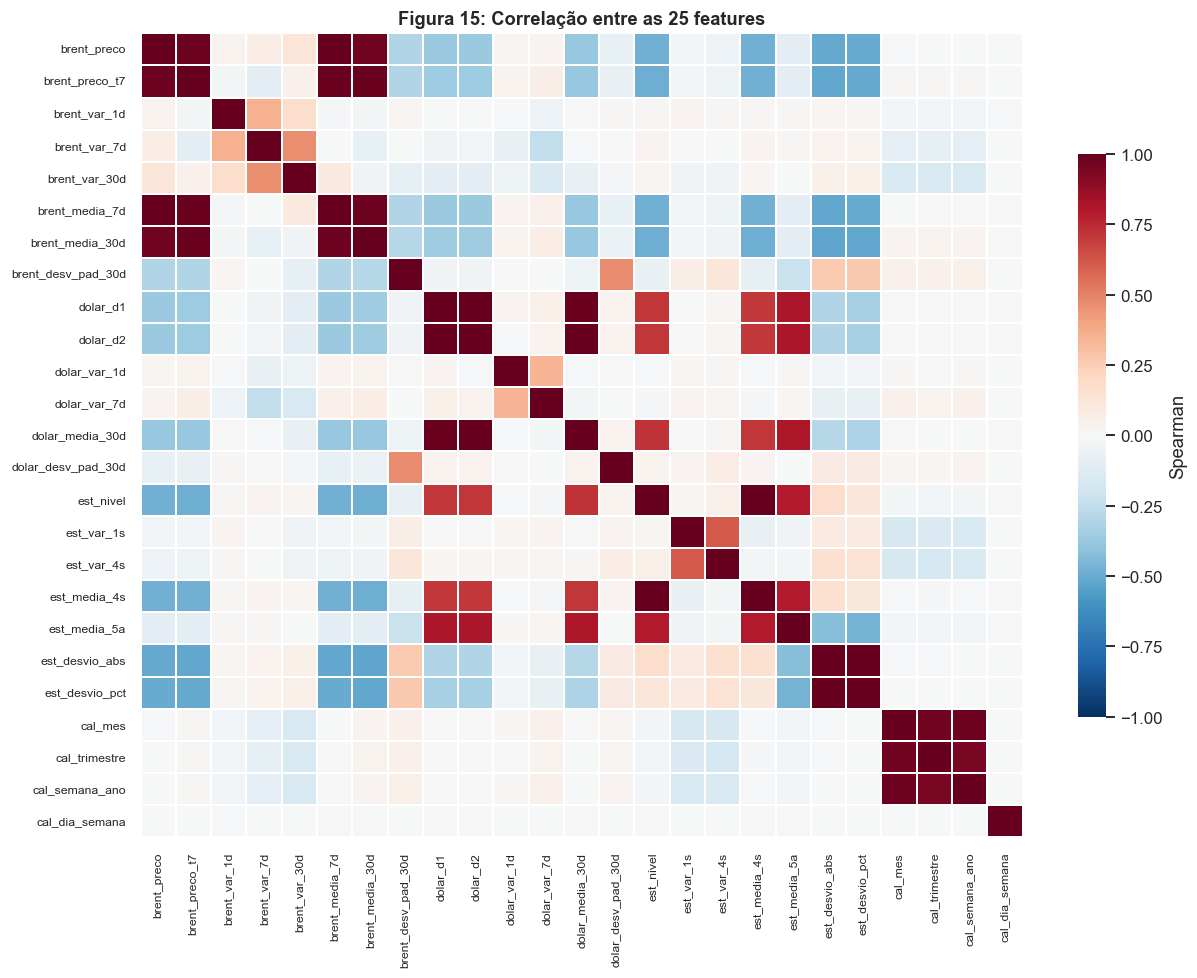

Pares com |correlação| >= 0,95: 14 (de 300)


Feature A,Feature B,Spearman
dolar_d1,dolar_d2,+0.999
est_desvio_abs,est_desvio_pct,+0.994
brent_preco,brent_media_7d,+0.994
est_nivel,est_media_4s,+0.993
dolar_d2,dolar_media_30d,+0.993
dolar_d1,dolar_media_30d,+0.992
brent_preco_t7,brent_media_7d,+0.991
brent_preco_t7,brent_media_30d,+0.987
brent_media_7d,brent_media_30d,+0.981
brent_preco,brent_preco_t7,+0.980


In [23]:
# 6.4 Redundância entre features (importa para a leitura do SHAP)
X = DS.loc[INI:, FEATURES]
corr = X.corr(method="spearman")
fig, ax = plt.subplots(figsize=(11.5, 9.0))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=0.2, linecolor="white", ax=ax, cbar_kws={"label": "Spearman", "shrink": 0.7})
ax.set_title("Figura 15: Correlação entre as 25 features"); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()
pares = [(a, b, corr.loc[a, b]) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if abs(corr.loc[a, b]) >= 0.95]
PARES_REDUNDANTES = pd.DataFrame(pares, columns=["Feature A", "Feature B", "Spearman"]).sort_values("Spearman", key=abs, ascending=False)
print(f"Pares com |correlação| >= 0,95: {len(PARES_REDUNDANTES)} (de {len(FEATURES)*(len(FEATURES)-1)//2})")
display(PARES_REDUNDANTES.style.hide(axis="index").format({"Spearman": "{:+.3f}"}))

### 6.5 A divisão do tempo: treino, validação e teste

```
2006                         2021  2022       2023  2024                 2026
│─────────────────────────────│──────│─────────│──────│────────────────────│
│          TREINO             │      VALIDAÇÃO       │       TESTE          │
│        ~16 anos             │       ~2 anos         │       ~3 anos        │
```

| Período | Datas | Uso |
|---|---|---|
| **Treino** | jan/2006 a dez/2021 | O modelo aprende aqui |
| **Validação** | jan/2022 a dez/2023 | Escolha de hiperparâmetros (Optuna), seleção de modelo, ablações |
| **Teste** | jan/2024 a set/2026 | **Só olhamos no final**, uma vez por modelo escolhido |

**Regras:** a ordem do tempo nunca é embaralhada. Nada do teste é usado para decidir nada. Dois cuidados específicos: (1) o treino contém os anos 2006-2018 em que a série do Ipeadata tem o defeito de datas (1.5), enquanto validação e teste estão inteiros em período limpo, então a **avaliação é confiável**; (2) o **choque de 2026 (Ormuz) está só no teste**, então nenhum modelo o conhece, o que é realista.

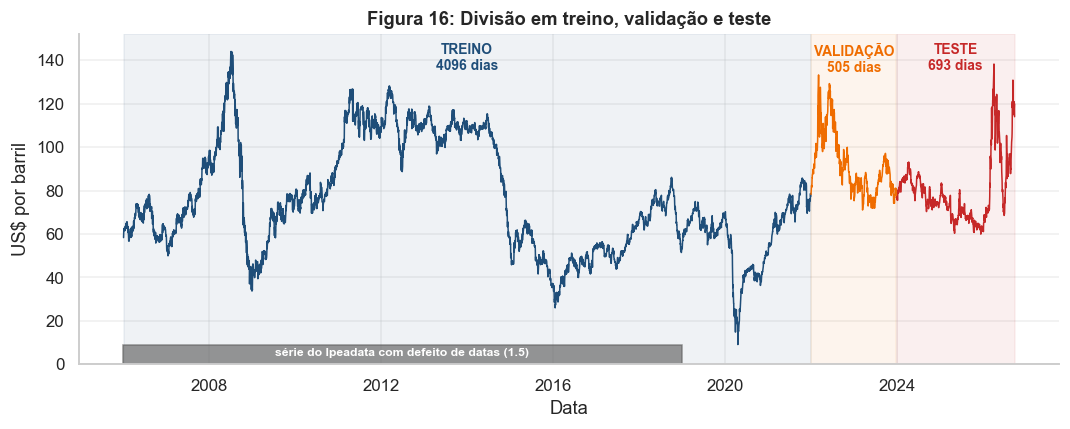

Período,Início,Fim,Dias úteis,Origens com alvo de 15 dias,Preço mín (US$),Preço máx (US$),DESV_PAD da VAR diária (%)
treino,14/02/2006,31/12/2021,4096,4096,9.1,143.9,3.28
validação,03/01/2022,29/12/2023,505,505,71.0,133.2,2.57
teste,02/01/2024,29/09/2026,693,678,59.9,138.2,2.74


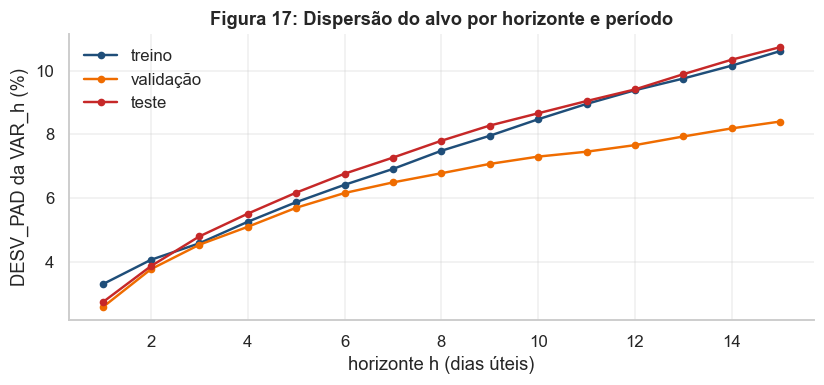

A dispersão do teste em h = 15 é 1.01x a do treino


In [24]:
# 6.5 Definição e figura da divisão
T_FIM = pd.Timestamp("2021-12-31"); V_INI, V_FIM = pd.Timestamp("2022-01-01"), pd.Timestamp("2023-12-31"); TE_INI = pd.Timestamp("2024-01-01")
DS["periodo"] = np.select([DS["data"] <= T_FIM, DS["data"] <= V_FIM], ["treino", "validação"], "teste")
COR_P = {"treino": AZUL, "validação": LARANJA, "teste": VERMELHO}

fig, ax = plt.subplots(figsize=(11.5, 3.9))
for nome, g in DS.groupby("periodo"):
    ax.plot(g["data"], g["brent_preco"], color=COR_P[nome], lw=1.0)
    ax.axvspan(g["data"].min(), g["data"].max(), color=COR_P[nome], alpha=0.07)
    ax.text(g["data"].min() + (g["data"].max() - g["data"].min()) / 2, 148, nome.upper() + "\n" + str(int((g.index >= INI).sum())) + " dias", ha="center", va="top", fontsize=9, fontweight="bold", color=COR_P[nome])
ax.axvspan(pd.Timestamp("2006-01-01"), pd.Timestamp("2018-12-31"), ymin=0, ymax=0.06, color=CINZA, alpha=0.65)
ax.text(pd.Timestamp("2012-07-01"), 4, "série do Ipeadata com defeito de datas (1.5)", ha="center", fontsize=8, color="white", fontweight="bold")
ax.set_ylim(0, 152); ax.set_title("Figura 16: Divisão em treino, validação e teste"); ax.set_xlabel("Data"); ax.set_ylabel("US$ por barril")
plt.show()

linhas = []
for nome in ["treino", "validação", "teste"]:
    g = DS[(DS["periodo"] == nome) & (DS.index >= INI)]
    linhas.append({"Período": nome, "Início": f"{g['data'].min():%d/%m/%Y}", "Fim": f"{g['data'].max():%d/%m/%Y}", "Dias úteis": len(g),
                   "Origens com alvo de 15 dias": int(g[ALVOS[-1]].notna().sum()), "Preço mín (US$)": g["brent_preco"].min(), "Preço máx (US$)": g["brent_preco"].max(),
                   "DESV_PAD da VAR diária (%)": g["brent_var_1d"].std()})
display(pd.DataFrame(linhas).style.hide(axis="index").format({"Preço mín (US$)": "{:.1f}", "Preço máx (US$)": "{:.1f}", "DESV_PAD da VAR diária (%)": "{:.2f}"}))

# o que o modelo vai tentar prever: dispersão do alvo em cada período e horizonte
disp = pd.DataFrame({nome: [DS.loc[(DS["periodo"] == nome) & (DS.index >= INI), f"VAR_{h}"].std() for h in range(1, H + 1)] for nome in COR_P}, index=range(1, H + 1))
fig, ax = plt.subplots(figsize=(7.6, 3.6))
for nome, cor in COR_P.items(): ax.plot(disp.index, disp[nome], "o-", color=cor, ms=4, lw=1.6, label=nome)
ax.set_xlabel("horizonte h (dias úteis)"); ax.set_ylabel("DESV_PAD da VAR_h (%)"); ax.set_title("Figura 17: Dispersão do alvo por horizonte e período")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
print(f"A dispersão do teste em h = 15 é {disp.loc[15,'teste']/disp.loc[15,'treino']:.2f}x a do treino")

## Bloco 7. Protocolo de validação e baselines

### 7.1 As regras do campeonato

Todos os modelos (baselines, Prophet, LightGBM) passam pelo **mesmo** protocolo, para que a comparação seja justa:

1. **Janela expansiva com reajuste periódico (walk-forward).** O modelo é treinado com tudo o que já aconteceu e reajustado a cada **63 pregões** (~1 trimestre). Entre reajustes, prevê sem ver o futuro.
2. **Sem sobreposição com o futuro (purga).** Uma amostra de treino de origem `j` e horizonte `h` só entra se `j + h ≤ t`, ou seja, se seu alvo já tinha acontecido na origem `t`. Isso evita que o treino "espie" o período que está sendo previsto.
3. **Uma previsão por origem e por horizonte:** para cada dia útil, 15 previsões (h = 1 … 15).
4. **Métricas, por horizonte** (preço em US$ reconstruído de `P[t] × exp(VAR_h/100)`):
   - **MAE, RMSE e MAPE** do preço;
   - **Ganho sobre o ingênuo** = 1 − (erro quadrático da VAR do modelo ÷ o do baseline ingênuo). Positivo = melhor que "amanhã = hoje";
   - **Acerto de direção** (o preço sobe ou desce?), comparado com apostar sempre na alta.
5. **Teste de Diebold-Mariano** com correção para sobreposição, para dizer se uma diferença entre modelos é real ou ruído.
6. **A validação decide, o teste confirma.** O teste só é lido no fim, uma vez por modelo escolhido.

### 7.2 Baselines
- **Ingênuo ("amanhã = hoje")**: prevê VAR = 0, ou seja, o preço de hoje vale para todos os dias.
- **Deriva (drift)**: prevê a VAR média histórica do treino. Serve de segundo piso e de teste do próprio protocolo (é um modelo que "aprende").

In [25]:
# 7.2 Protocolo: walk-forward com purga, reajuste a cada REFIT pregões
REFIT = 63
ARR_Y = {h: DS[f"VAR_{h}"].values for h in range(1, H + 1)}
DATAS = DS["data"].values

def origens(inicio, fim, h):
    """índices de origem dentro do período, com alvo de h dias já observável na base"""
    m = (DS["data"] >= inicio) & (DS["data"] <= fim) & (DS.index >= INI) & (DS.index + h < len(DS))
    return np.where(m.values)[0]

def walk_forward(fit_predict, inicio, fim, h, treino_inicio=None, refit=REFIT):
    """fit_predict(idx_treino, idx_prever, h) -> VAR prevista (array). Retorna DataFrame com real e previsto por origem."""
    idx = origens(inicio, fim, h)
    ini_tr = INI if treino_inicio is None else max(INI, int(np.argmax((DS["data"] >= treino_inicio).values)))
    saidas = []
    for k in range(0, len(idx), refit):
        bloco = idx[k:k + refit]
        t0 = bloco[0]
        treino = np.arange(ini_tr, t0 - h + 1)          # purga: j + h <= t0
        assert len(treino) > 100 and treino[-1] + h <= t0, "treino insuficiente ou com sobreposição"
        pred = np.asarray(fit_predict(treino, bloco, h), dtype=float)
        saidas.append(pd.DataFrame({"i": bloco, "h": h, "real_var": ARR_Y[h][bloco], "pred_var": pred}))
    R = pd.concat(saidas, ignore_index=True)
    R["data"] = DATAS[R["i"].values]; R["preco_t"] = PRECO[R["i"].values]
    R["preco_real"] = R["preco_t"] * np.exp(R["real_var"] / 100); R["preco_pred"] = R["preco_t"] * np.exp(R["pred_var"] / 100)
    return R

def metricas(R, ref=None):
    """ref: previsões do ingênuo nas mesmas origens, para o ganho"""
    e = R["preco_pred"] - R["preco_real"]
    saida = {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "MAPE": (e.abs() / R["preco_real"]).mean() * 100}
    ev = (R["pred_var"] - R["real_var"]).values
    saida["ganho_vs_ingenuo"] = np.nan if ref is None else 1 - (ev ** 2).mean() / ((ref["pred_var"] - ref["real_var"]) ** 2).mean()
    ap = R["pred_var"].values != 0
    saida["acerto_direcao"] = np.nan if not ap.any() else ((R["pred_var"].values[ap] > 0) == (R["real_var"].values[ap] > 0)).mean() * 100
    saida["sempre_alta"] = max((R["real_var"] > 0).mean(), (R["real_var"] <= 0).mean()) * 100
    return saida

def dm_teste(r_a, r_b, h):
    """Diebold-Mariano (perda quadrática da VAR), variância de longo prazo com h-1 defasagens. d = erro_a^2 - erro_b^2: negativo = A melhor."""
    d = ((r_a["pred_var"] - r_a["real_var"]) ** 2).values - ((r_b["pred_var"] - r_b["real_var"]) ** 2).values
    n = len(d); dm = d.mean(); dc = d - dm
    gam = [np.dot(dc[k:], dc[:n - k]) / n for k in range(h)]
    var_lp = gam[0] + 2 * sum((1 - k / h) * gam[k] for k in range(1, h))
    est = dm / np.sqrt(max(var_lp, 1e-12) / n)
    return est, 2 * (1 - stats.norm.cdf(abs(est)))

# modelos de referência
def fit_ingenuo(idx_tr, idx_pr, h): return np.zeros(len(idx_pr))
def fit_deriva(idx_tr, idx_pr, h):  return np.full(len(idx_pr), ARR_Y[h][idx_tr].mean())

PERIODOS = {"validação": (V_INI, V_FIM), "teste": (TE_INI, DS["data"].max())}
BASE_RES = {}
for per, (a, b) in PERIODOS.items():
    for nome, f in [("ingênuo", fit_ingenuo), ("deriva", fit_deriva)]:
        BASE_RES[(per, nome)] = {h: walk_forward(f, a, b, h) for h in range(1, H + 1)}

# verificações do protocolo
for per in PERIODOS:
    R = BASE_RES[(per, "ingênuo")][H]
    assert (R["pred_var"] == 0).all() and np.allclose(R["preco_pred"], R["preco_t"]), "ingênuo deveria repetir o preço de hoje"
    assert (R["data"] >= PERIODOS[per][0]).all() and (R["data"] <= PERIODOS[per][1]).all(), "origem fora do período"
print({per: {h: len(BASE_RES[(per, 'ingênuo')][h]) for h in (1, 15)} for per in PERIODOS})

{'validação': {1: 505, 15: 505}, 'teste': {1: 692, 15: 678}}


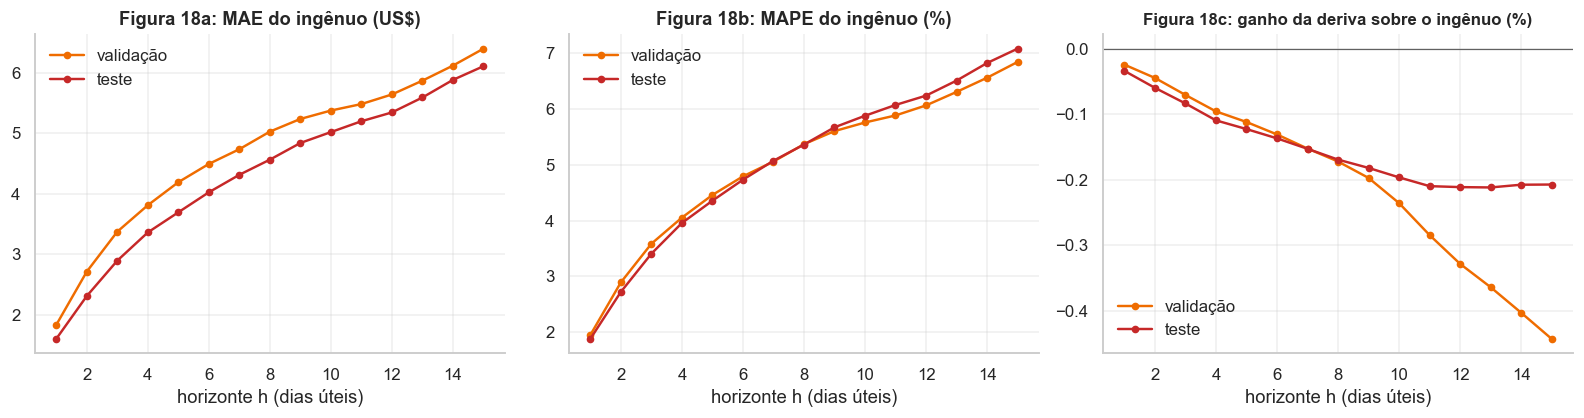

Período,h,Origens,MAE ingênuo (US$),MAPE ingênuo (%),RMSE ingênuo (US$),MAE deriva (US$),Ganho da deriva,DM p-valor,Deriva acerta direção (%),Sempre alta (%)
validação,1,505,1.83,1.95,2.56,1.83,-0.0%,0.512,53.7,53.7
validação,5,505,4.19,4.46,5.64,4.20,-0.1%,0.432,51.1,51.1
validação,10,505,5.38,5.76,7.06,5.39,-0.2%,0.427,48.9,51.1
validação,15,505,6.40,6.84,8.10,6.42,-0.4%,0.374,47.3,52.7
teste,1,692,1.60,1.88,2.58,1.60,-0.0%,0.123,50.6,50.6
teste,5,688,3.70,4.36,5.62,3.70,-0.1%,0.160,50.7,50.7
teste,10,683,5.02,5.88,7.80,5.03,-0.2%,0.226,50.8,50.8
teste,15,678,6.11,7.08,9.65,6.12,-0.2%,0.371,50.4,50.4


validação: MAE médio do ingênuo nos 15 horizontes US$ 4.69 | MAPE médio 5.01% | ganho médio da deriva -0.2%
teste: MAE médio do ingênuo nos 15 horizontes US$ 4.32 | MAPE médio 5.05% | ganho médio da deriva -0.2%


In [26]:
# 7.3 Resultado dos baselines por horizonte
linhas = []
for per in PERIODOS:
    for h in range(1, H + 1):
        ing, der = BASE_RES[(per, "ingênuo")][h], BASE_RES[(per, "deriva")][h]
        mi, md_ = metricas(ing), metricas(der, ref=ing)
        z, p = dm_teste(der, ing, h)
        linhas.append({"Período": per, "h": h, "Origens": len(ing), "MAE ingênuo (US$)": mi["MAE"], "MAPE ingênuo (%)": mi["MAPE"], "RMSE ingênuo (US$)": mi["RMSE"],
                       "MAE deriva (US$)": md_["MAE"], "Ganho da deriva": md_["ganho_vs_ingenuo"], "DM p-valor": p, "Deriva acerta direção (%)": md_["acerto_direcao"], "Sempre alta (%)": md_["sempre_alta"]})
BASELINES = pd.DataFrame(linhas)

fig, axs = plt.subplots(1, 3, figsize=(14.5, 3.9))
for per, cor in [("validação", LARANJA), ("teste", VERMELHO)]:
    s = BASELINES[BASELINES["Período"] == per]
    axs[0].plot(s["h"], s["MAE ingênuo (US$)"], "o-", color=cor, ms=4, lw=1.6, label=per)
    axs[1].plot(s["h"], s["MAPE ingênuo (%)"], "o-", color=cor, ms=4, lw=1.6, label=per)
    axs[2].plot(s["h"], s["Ganho da deriva"] * 100, "o-", color=cor, ms=4, lw=1.6, label=per)
axs[0].set_title("Figura 18a: MAE do ingênuo (US$)"); axs[1].set_title("Figura 18b: MAPE do ingênuo (%)"); axs[2].set_title("Figura 18c: ganho da deriva sobre o ingênuo (%)", fontsize=11)
axs[2].axhline(0, color=CINZA, lw=0.8)
for a in axs: a.set_xlabel("horizonte h (dias úteis)"); a.legend(frameon=False)
plt.tight_layout(); plt.show()

sel = BASELINES[BASELINES["h"].isin([1, 5, 10, 15])]
display(sel.style.hide(axis="index").format({"MAE ingênuo (US$)": "{:.2f}", "MAPE ingênuo (%)": "{:.2f}", "RMSE ingênuo (US$)": "{:.2f}", "MAE deriva (US$)": "{:.2f}",
                                           "Ganho da deriva": "{:+.1%}", "DM p-valor": "{:.3f}", "Deriva acerta direção (%)": "{:.1f}", "Sempre alta (%)": "{:.1f}"}))
for per in PERIODOS:
    s = BASELINES[BASELINES["Período"] == per]
    print(f"{per}: MAE médio do ingênuo nos 15 horizontes US$ {s['MAE ingênuo (US$)'].mean():.2f} | MAPE médio {s['MAPE ingênuo (%)'].mean():.2f}% | ganho médio da deriva {s['Ganho da deriva'].mean():+.1%}")

In [27]:
# 7.4 Exporta a base de features (reutilizada nas fases seguintes e no app)
SAIDA = BASE / "features_modelagem.parquet"
cols_saida = ["data", "periodo"] + FEATURES + CICLICAS + ALVOS
DS.loc[INI:, cols_saida].to_parquet(SAIDA, index=False)
print(f"Salvo: {SAIDA.name} | {len(DS.loc[INI:])} linhas x {len(cols_saida)} colunas")

Salvo: features_modelagem.parquet | 5294 linhas x 46 colunas


## 7.5 Leitura da Fase 2

**1. As features estão prontas e sem vazamento.** São 25 features (mais 4 cíclicas candidatas) e 15 alvos (`VAR_1` a `VAR_15`), salvos em `00_Base_TC/features_modelagem.parquet` (5.294 linhas). O teste de truncamento recalculou as features só com dados até `t` em 40 datas aleatórias e obteve resultado idêntico ao da base inteira.

**2. Há bastante redundância entre as features** (14 de 300 pares com correlação acima de 0,95):
- `dolar_d1` e `dolar_d2` (0,999), `est_desvio_abs` e `est_desvio_pct` (0,994), e o preço do Brent com suas médias móveis (0,97 a 0,99);
- no calendário, mês, trimestre e semana do ano são quase a mesma informação (0,95 a 0,98).

Isso não prejudica a previsão com árvores, mas **divide o crédito no SHAP** entre colunas parecidas. Por isso a leitura do SHAP será feita **por grupo** (Brent, Dólar, Estoques, Calendário) e não só feature a feature.

**3. Um risco a testar na Fase 3: várias features estão em nível** (preço, médias, dólar, estoque). Modelos de árvore podem decorar "regimes" de preço em vez de aprender relações. Testaremos também versões relativas (por exemplo, o preço em relação à média de 30 dias).

**4. A divisão é boa para avaliar.** Treino de 14/02/2006 a 31/12/2021 (4.096 dias), validação de 2022 a 2023 (505 dias) e teste de 2024 a set/2026 (693 dias, 678 com alvo de 15 dias). Validação e teste estão inteiros em período limpo da série. O choque de 2026 está só no teste.

**5. O piso a bater é difícil.** O baseline ingênuo ("amanhã = hoje") erra:

| Horizonte | MAPE na validação | MAPE no teste | MAE no teste |
|---|---|---|---|
| 1 dia | 1,95% | 1,88% | US$ 1,60 |
| 5 dias | 4,46% | 4,36% | US$ 3,70 |
| 10 dias | 5,76% | 5,88% | US$ 5,02 |
| **15 dias** | **6,84%** | **7,08%** | **US$ 6,11** |

Em média nos 15 horizontes: MAPE de 5,01% (validação) e 5,05% (teste).

**6. "Aprender" a média histórica não ajuda.** A deriva fica entre 0,0% e 0,4% **pior** que o ingênuo, com p-valor de Diebold-Mariano de 0,12 a 0,51 (nunca significativo). O protocolo está funcionando: um modelo que não tem informação útil termina igual ou pior que o ingênuo.

**7. Direção não rende.** Apostar sempre no lado mais frequente acerta de 50,4% a 53,7% das vezes, e a deriva fica no mesmo nível. Reforça o que a EDA apontou: o valor do modelo está em **nível e faixa**.

### O que um modelo precisa provar para ser considerado melhor
Ganho positivo sobre o ingênuo na validação, com Diebold-Mariano significativo (p < 0,05) em pelo menos parte dos horizontes, **e** manter o ganho no teste. Com ~500 origens sobrepostas, o poder estatístico é limitado, e diferenças pequenas serão ambíguas. Nesse caso reportaremos como empate, como fizemos na análise anterior.

### Para o seu portão (Fase 2)
- **Aprovar as 25 features** e o protocolo (janela expansiva, reajuste a cada 63 pregões, purga, métricas).
- **Janela de treino:** com a sua divisão, o treino é 2006-2021 (inclui os anos com defeito). Uma variante só com 2019-2021 teria apenas 3 anos, dominados pelo COVID. Proponho manter 2006-2021 como padrão e testar a variante curta apenas como sensibilidade na Fase 3.
- **Datas dos eventos** marcadas como "conhecimento geral" (tabela 2.1) ainda precisam de checagem em fonte.

---
# FASE 3. Modelagem

## Bloco 8. Os modelos

### 8.1 O que vamos comparar

| Modelo | Como prevê | Papel |
|---|---|---|
| **Ingênuo** | "amanhã = hoje" (VAR = 0) | Piso. É o que todo modelo precisa superar |
| **Deriva** | VAR média histórica | Segundo piso (já visto na Fase 2) |
| **Prophet** | Tendência + sazonalidade anual e semanal (+ regressores defasados), aplicadas **sobre o último preço real** | Modelo de séries temporais clássico |
| **LightGBM + Optuna** | **Um modelo por horizonte** (h = 1 a 15), cada um prevendo a `VAR_h` a partir das features | Candidato principal |

**Como cada modelo é usado**
- **Prophet** prevê a *evolução esperada* do log-preço. Usamos a variação prevista entre `t` e `t+h`, aplicada ao preço real de `t`: `VAR_h = 100 × (ŷ[t+h] − ŷ[t])`. Assim ele é comparável aos demais, que partem do último preço. Os regressores (dólar, estoque e DESV_PAD) entram **defasados em 15 dias úteis**, o que garante que valham mesmo para o dia `t+h` (qualquer `h ≤ 15`) sem espiar o futuro.
- **LightGBM** é treinado separadamente para cada `h`, sempre com a purga do protocolo (7.1).

**Disciplina de seleção**
- **A validação (2022-2023) decide** os hiperparâmetros (Optuna) e o conjunto de features.
- **O teste (2024-2026) é lido uma única vez**, ao final (8.7), com tudo já congelado.
- O Optuna escolhe também entre dois conjuntos de features: as **25 originais (em nível)** e uma versão **relativa** com 18 (preço em relação à média, etc.), para checar o risco de o modelo "decorar" regimes de preço.

In [28]:
# 8.2 Preparação
import json, time, logging, optuna, lightgbm as lgb
from prophet import Prophet
optuna.logging.set_verbosity(optuna.logging.WARNING)
for _n in ("cmdstanpy", "prophet"):
    _lg = logging.getLogger(_n); _lg.handlers = [logging.NullHandler()]; _lg.propagate = False; _lg.setLevel(logging.CRITICAL)
ART = BASE.parent / "01_Notebook" / "artefatos"; ART.mkdir(exist_ok=True)

# versão relativa das features (sem níveis absolutos)
DS["rel_brent_vs_media7"]  = (DS["brent_preco"] / DS["brent_media_7d"] - 1) * 100
DS["rel_brent_vs_media30"] = (DS["brent_preco"] / DS["brent_media_30d"] - 1) * 100
DS["rel_dolar_vs_media30"] = (DS["dolar_d1"] / DS["dolar_media_30d"] - 1) * 100
DS["rel_est_vs_media4s"]   = (DS["est_nivel"] / DS["est_media_4s"] - 1) * 100
FEATURES_REL = ["brent_var_1d", "brent_var_7d", "brent_var_30d", "brent_desv_pad_30d", "rel_brent_vs_media7", "rel_brent_vs_media30",
                "dolar_var_1d", "dolar_var_7d", "dolar_desv_pad_30d", "rel_dolar_vs_media30",
                "est_var_1s", "est_var_4s", "est_desvio_pct", "rel_est_vs_media4s"] + FEATURES_CAL
CONJUNTOS = {"nível (25)": FEATURES, "relativo (18)": FEATURES_REL}
XM = {k: DS[v].values.astype(float) for k, v in CONJUNTOS.items()}
for k, v in CONJUNTOS.items():
    assert not np.isnan(XM[k][INI:]).any(), f"vazio no conjunto {k}"

def mape_preco(R): return float((R["preco_pred"] - R["preco_real"]).abs().div(R["preco_real"]).mean() * 100)
def montar_resultado(idx, h, pred):
    R = pd.DataFrame({"i": idx, "h": h, "real_var": ARR_Y[h][idx], "pred_var": np.asarray(pred, dtype=float)})
    R["data"] = DATAS[R["i"].values]; R["preco_t"] = PRECO[R["i"].values]
    R["preco_real"] = R["preco_t"] * np.exp(R["real_var"] / 100); R["preco_pred"] = R["preco_t"] * np.exp(R["pred_var"] / 100)
    return R

MAPE_ING_VAL = {h: mape_preco(BASE_RES[("validação", "ingênuo")][h]) for h in range(1, H + 1)}
N_JOBS = 6
print("Conjuntos de features:", {k: len(v) for k, v in CONJUNTOS.items()})
print("MAPE do ingênuo na validação, h = 1, 5, 10, 15:", [round(MAPE_ING_VAL[h], 2) for h in (1, 5, 10, 15)])

Conjuntos de features: {'nível (25)': 25, 'relativo (18)': 18}
MAPE do ingênuo na validação, h = 1, 5, 10, 15: [1.95, 4.46, 5.76, 6.84]


### 8.3 LightGBM com Optuna

O Optuna testa combinações de hiperparâmetros, **só na validação**, e minimiza a razão `MAPE do modelo ÷ MAPE do ingênuo` (média dos horizontes 1, 5, 10 e 15). Razão abaixo de 1 = melhor que o ingênuo. A busca escolhe também a função de perda (quadrática ou Huber, que é menos sensível aos choques extremos) e o conjunto de features.

*Cuidado conhecido:* como o Optuna ajusta e a validação avalia no mesmo período, a validação fica **levemente otimista**. É por isso que o teste existe.

In [29]:
# 8.3 Optuna para o LightGBM (resultado em cache: artefatos/lgbm_params.json)
H_TUNE, REFIT_TUNE, N_TRIALS = [1, 5, 10, 15], 126, 60
RETUNAR = False
def fabrica_lgbm(params, conjunto):
    Xc = XM[conjunto]
    def fit_predict(idx_tr, idx_pr, h):
        m = lgb.LGBMRegressor(**params, random_state=SEMENTE, verbose=-1, n_jobs=N_JOBS)
        m.fit(Xc[idx_tr], ARR_Y[h][idx_tr])
        return m.predict(Xc[idx_pr])
    return fit_predict

def parametros(trial):
    obj = trial.suggest_categorical("objetivo", ["regression", "huber"])
    p = dict(objective=obj, n_estimators=trial.suggest_int("n_estimators", 40, 400), learning_rate=trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
             num_leaves=trial.suggest_int("num_leaves", 3, 15), max_depth=trial.suggest_int("max_depth", 2, 5),
             min_child_samples=trial.suggest_int("min_child_samples", 30, 300), subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
             colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0), reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
             reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 50, log=True))
    if obj == "huber": p["alpha"] = trial.suggest_float("huber_alpha", 1.0, 10.0)
    return p

def objetivo_lgbm(trial):
    conj = trial.suggest_categorical("conjunto", list(CONJUNTOS))
    p = parametros(trial)
    razoes = [mape_preco(walk_forward(fabrica_lgbm(p, conj), V_INI, V_FIM, h, refit=REFIT_TUNE)) / MAPE_ING_VAL[h] for h in H_TUNE]
    return float(np.mean(razoes))

arq_lgbm = ART / "lgbm_params.json"
if arq_lgbm.exists() and not RETUNAR:
    SALVO = json.loads(arq_lgbm.read_text(encoding="utf-8")); print("Optuna: usando o resultado em cache.")
    LGBM_PARAMS, LGBM_CONJ, LGBM_TRIALS = SALVO["params"], SALVO["conjunto"], pd.read_csv(ART / "lgbm_trials.csv")
else:
    t0 = time.time()
    estudo = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEMENTE))
    estudo.optimize(objetivo_lgbm, n_trials=N_TRIALS, show_progress_bar=False)
    bt = estudo.best_trial
    LGBM_CONJ = bt.params["conjunto"]; LGBM_PARAMS = parametros(optuna.trial.FixedTrial({k: v for k, v in bt.params.items() if k != "conjunto"}))
    LGBM_TRIALS = estudo.trials_dataframe()[["number", "value", "params_conjunto", "params_objetivo"]].rename(columns={"params_conjunto": "conjunto", "params_objetivo": "objetivo"})
    arq_lgbm.write_text(json.dumps({"params": LGBM_PARAMS, "conjunto": LGBM_CONJ, "melhor_razao": bt.value, "trials": N_TRIALS, "minutos": round((time.time() - t0) / 60, 1)}, indent=1), encoding="utf-8")
    LGBM_TRIALS.to_csv(ART / "lgbm_trials.csv", index=False)
    SALVO = json.loads(arq_lgbm.read_text(encoding="utf-8")); print(f"Optuna concluído em {(time.time()-t0)/60:.1f} min")
print(f"Melhor razão MAPE/ingênuo na afinação: {SALVO['melhor_razao']:.4f} | conjunto: {LGBM_CONJ}")
display(pd.DataFrame([{k: (round(v, 4) if isinstance(v, float) else v) for k, v in LGBM_PARAMS.items()}]).T.rename(columns={0: "valor"}))

Optuna: usando o resultado em cache.
Melhor razão MAPE/ingênuo na afinação: 0.9989 | conjunto: nível (25)


,valor
objective,regression
n_estimators,41
learning_rate,0.0059
num_leaves,15
max_depth,5
min_child_samples,116
subsample,0.9982
subsample_freq,1
colsample_bytree,0.6301
reg_alpha,1.5581


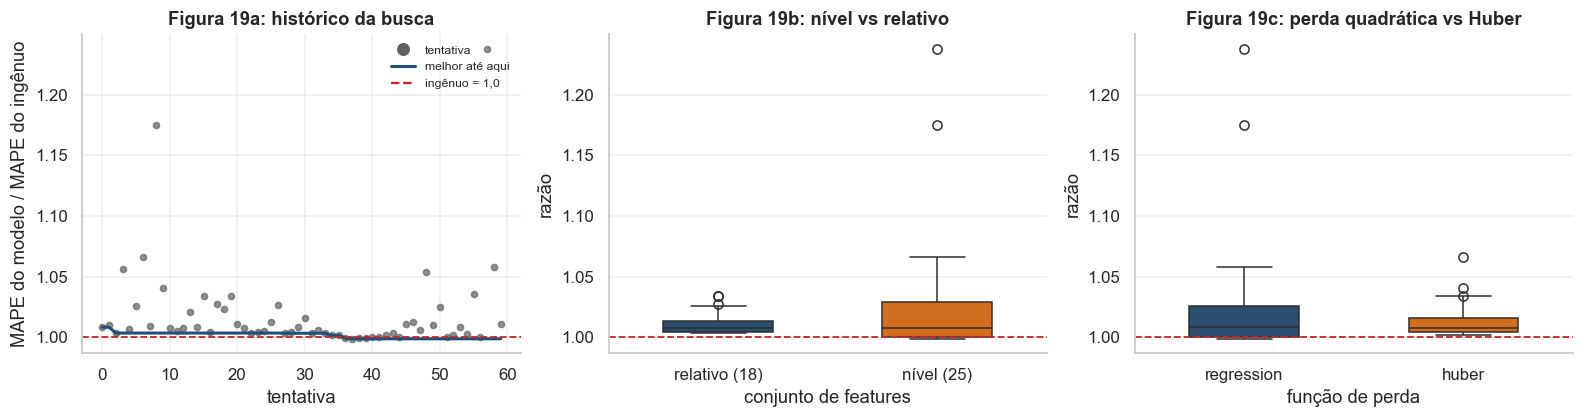

,tentativas,melhor,mediana
conjunto,,,
nível (25),32,0.9989,1.0074
relativo (18),28,1.0035,1.0081


,tentativas,melhor,mediana
objetivo,,,
huber,29,1.0018,1.0074
regression,31,0.9989,1.0085


Tentativas melhores que o ingênuo (razão < 1): 4 de 60


In [30]:
# 8.3b O que o Optuna aprendeu
fig, axs = plt.subplots(1, 3, figsize=(14.5, 3.9))
tr = LGBM_TRIALS.sort_values("number")
axs[0].plot(tr["number"], tr["value"], "o", ms=4, color=CINZA, alpha=0.7); axs[0].plot(tr["number"], tr["value"].cummin(), "-", color=AZUL, lw=2)
axs[0].axhline(1.0, color=VERMELHO, ls="--", lw=1.2); axs[0].set_xlabel("tentativa"); axs[0].set_ylabel("MAPE do modelo / MAPE do ingênuo")
axs[0].set_title("Figura 19a: histórico da busca"); axs[0].legend(handles=[bolinha(CINZA, "tentativa"), Line2D([], [], color=AZUL, lw=2, label="melhor até aqui"), Line2D([], [], color=VERMELHO, ls="--", label="ingênuo = 1,0")], frameon=False, fontsize=8, loc="upper right")
sns.boxplot(data=tr, x="conjunto", y="value", hue="conjunto", palette=[AZUL, LARANJA], ax=axs[1], legend=False, width=0.5)
axs[1].axhline(1.0, color=VERMELHO, ls="--", lw=1.2); axs[1].set_xlabel("conjunto de features"); axs[1].set_ylabel("razão"); axs[1].set_title("Figura 19b: nível vs relativo")
sns.boxplot(data=tr, x="objetivo", y="value", hue="objetivo", palette=[AZUL, LARANJA], ax=axs[2], legend=False, width=0.5)
axs[2].axhline(1.0, color=VERMELHO, ls="--", lw=1.2); axs[2].set_xlabel("função de perda"); axs[2].set_ylabel("razão"); axs[2].set_title("Figura 19c: perda quadrática vs Huber")
plt.tight_layout(); plt.show()
res_c = tr.groupby("conjunto")["value"].agg(["count", "min", "median"]); res_o = tr.groupby("objetivo")["value"].agg(["count", "min", "median"])
display(res_c.round(4).rename(columns={"count": "tentativas", "min": "melhor", "median": "mediana"})); display(res_o.round(4).rename(columns={"count": "tentativas", "min": "melhor", "median": "mediana"}))
print(f"Tentativas melhores que o ingênuo (razão < 1): {(tr['value'] < 1).sum()} de {len(tr)}")

In [31]:
# 8.4 LightGBM final: todos os horizontes, validação, reajuste a cada 63 pregões
t0 = time.time()
RES = {"validação": {"ingênuo": BASE_RES[("validação", "ingênuo")], "deriva": BASE_RES[("validação", "deriva")]}, "teste": {}}
RES["validação"]["LightGBM"] = {h: walk_forward(fabrica_lgbm(LGBM_PARAMS, LGBM_CONJ), V_INI, V_FIM, h) for h in range(1, H + 1)}
print(f"LightGBM na validação: {time.time()-t0:.0f} s")

LightGBM na validação: 10 s


### 8.5 Prophet

O Prophet é ajustado a cada 63 pregões sobre o **log do preço** (tendência com pontos de mudança + sazonalidade anual e semanal). Dois ajustes finos pelo Optuna, na validação: a flexibilidade da tendência e da sazonalidade, e se **vale incluir os três regressores defasados** (dólar relativo à média de 30 dias, desvio sazonal do estoque e DESV_PAD 30D do Brent).

In [32]:
# 8.5 Prophet: ajuste em blocos e previsão da variação esperada sobre o último preço real
LAG_REG = 15
REG_BASE = ["rel_dolar_vs_media30", "est_desvio_pct", "brent_desv_pad_30d"]
REG_L = [r + "_L15" for r in REG_BASE]
for r in REG_BASE: DS[r + "_L15"] = DS[r].shift(LAG_REG)
INI_P = INI + LAG_REG          # primeiro dia com os regressores defasados preenchidos

def prophet_walk_forward(p, inicio, fim, hs, refit=REFIT):
    """p: dict(cps, sps, cr, reg). Ajusta com dados até a primeira origem do bloco; VAR_h = 100*(yhat[t+h]-yhat[t])."""
    saidas = {h: [] for h in hs}
    idx_all = origens(inicio, fim, min(hs))
    for k in range(0, len(idx_all), refit):
        t0 = idx_all[k]
        tr = np.arange(INI_P, t0 + 1)
        d = pd.DataFrame({"ds": DATAS[tr], "y": np.log(PRECO[tr])})
        m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False, changepoint_prior_scale=p["cps"],
                    seasonality_prior_scale=p["sps"], changepoint_range=p["cr"])
        if p["reg"]:
            for r in REG_L: m.add_regressor(r); d[r] = DS[r].values[tr]
        m.fit(d)
        fim_i = min(t0 + refit + H, len(DS))
        fut = pd.DataFrame({"ds": DATAS[t0:fim_i]})
        if p["reg"]:
            for r in REG_L: fut[r] = DS[r].values[t0:fim_i]
        yhat = m.predict(fut)["yhat"].values
        for h in hs:
            idx = origens(inicio, fim, h); idx = idx[(idx >= t0) & (idx < t0 + refit)]
            if len(idx): saidas[h].append(montar_resultado(idx, h, 100 * (yhat[idx + h - t0] - yhat[idx - t0])))
    return {h: pd.concat(v, ignore_index=True) for h, v in saidas.items()}

H_TUNE_P, N_TRIALS_P = [5, 15], 10
def objetivo_prophet(trial):
    p = dict(cps=trial.suggest_float("cps", 0.001, 0.5, log=True), sps=trial.suggest_float("sps", 0.01, 10, log=True),
             cr=trial.suggest_float("cr", 0.8, 0.95), reg=trial.suggest_categorical("reg", [False, True]))
    R = prophet_walk_forward(p, V_INI, V_FIM, H_TUNE_P, refit=126)
    return float(np.mean([mape_preco(R[h]) / MAPE_ING_VAL[h] for h in H_TUNE_P]))

arq_p = ART / "prophet_params.json"
if arq_p.exists() and not RETUNAR:
    PSALVO = json.loads(arq_p.read_text(encoding="utf-8")); print("Optuna (Prophet): usando o resultado em cache.")
else:
    t0 = time.time()
    est_p = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEMENTE))
    est_p.optimize(objetivo_prophet, n_trials=N_TRIALS_P, show_progress_bar=False)
    PSALVO = {"params": est_p.best_params, "melhor_razao": est_p.best_value, "trials": N_TRIALS_P, "minutos": round((time.time() - t0) / 60, 1)}
    arq_p.write_text(json.dumps(PSALVO, indent=1), encoding="utf-8"); print(f"Optuna (Prophet) concluído em {(time.time()-t0)/60:.1f} min")
PROPHET_PARAMS = PSALVO["params"]
print(f"Melhor razão MAPE/ingênuo na afinação do Prophet: {PSALVO['melhor_razao']:.4f} | parâmetros: {PROPHET_PARAMS}")
t0 = time.time()
RES["validação"]["Prophet"] = prophet_walk_forward(PROPHET_PARAMS, V_INI, V_FIM, list(range(1, H + 1)))
print(f"Prophet na validação: {time.time()-t0:.0f} s")

Optuna (Prophet): usando o resultado em cache.
Melhor razão MAPE/ingênuo na afinação do Prophet: 0.9962 | parâmetros: {'cps': 0.001136467270001117, 'sps': 8.123245085588687, 'cr': 0.9248663961200633, 'reg': False}


Prophet na validação: 20 s


### 8.6 Resultado na validação (2022-2023)

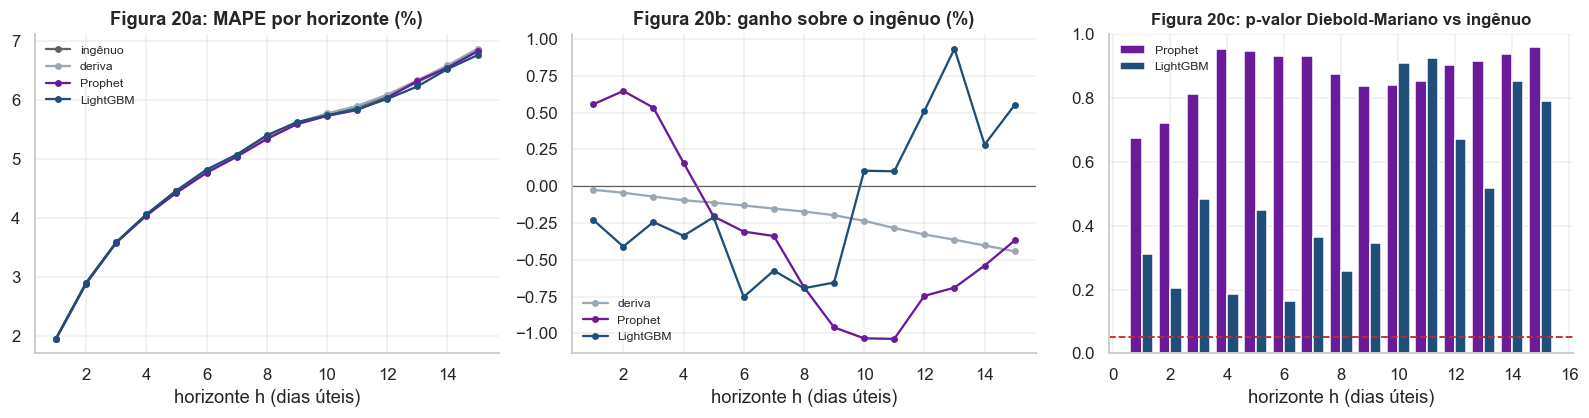

Modelo,h,MAPE (%),MAE (US$),RMSE (US$),Ganho vs ingênuo,DM p-valor,Acerto direção (%),Sempre alta (%)
ingênuo,1,1.95,1.83,2.56,+0.0%,—,—,53.7
deriva,1,1.95,1.83,2.56,-0.0%,0.512,53.7,53.7
Prophet,1,1.95,1.84,2.56,+0.6%,0.673,50.7,53.7
LightGBM,1,1.96,1.84,2.57,-0.2%,0.312,51.9,53.7
ingênuo,5,4.46,4.19,5.64,+0.0%,—,—,51.1
deriva,5,4.46,4.20,5.65,-0.1%,0.432,51.1,51.1
Prophet,5,4.43,4.16,5.65,-0.2%,0.948,52.9,51.1
LightGBM,5,4.47,4.20,5.64,-0.2%,0.449,49.3,51.1
ingênuo,10,5.76,5.38,7.06,+0.0%,—,—,51.1
deriva,10,5.77,5.39,7.07,-0.2%,0.427,48.9,51.1


,MAPE_medio,ganho_medio,horizontes_melhores,horizontes_significativos
Modelo,,,,
ingênuo,5.01,+0.00%,0,0
deriva,5.02,-0.20%,0,0
Prophet,4.99,-0.33%,4,0
LightGBM,5.00,-0.11%,6,0


In [33]:
# 8.6 Comparação na validação
MODELOS = ["ingênuo", "deriva", "Prophet", "LightGBM"]
COR_M = {"ingênuo": CINZA, "deriva": "#9aa7b4", "Prophet": ROXO, "LightGBM": AZUL}

def tabela(per):
    linhas = []
    for h in range(1, H + 1):
        ing = RES[per]["ingênuo"][h]
        for nome in MODELOS:
            R = RES[per][nome][h]; m = metricas(R, ref=ing)
            p = np.nan if nome == "ingênuo" else dm_teste(R, ing, h)[1]
            linhas.append({"Modelo": nome, "h": h, "MAPE (%)": m["MAPE"], "MAE (US$)": m["MAE"], "RMSE (US$)": m["RMSE"], "Ganho vs ingênuo": m["ganho_vs_ingenuo"],
                           "DM p-valor": p, "Acerto direção (%)": m["acerto_direcao"], "Sempre alta (%)": m["sempre_alta"]})
    return pd.DataFrame(linhas)

def figura_modelos(T, titulo):
    fig, axs = plt.subplots(1, 3, figsize=(14.5, 3.9))
    for nome in MODELOS:
        s = T[T["Modelo"] == nome]
        axs[0].plot(s["h"], s["MAPE (%)"], "o-", ms=3.5, lw=1.5, color=COR_M[nome], label=nome)
        if nome != "ingênuo": axs[1].plot(s["h"], s["Ganho vs ingênuo"] * 100, "o-", ms=3.5, lw=1.5, color=COR_M[nome], label=nome)
    for nome in ["Prophet", "LightGBM"]:
        s = T[T["Modelo"] == nome]; axs[2].bar(s["h"] + (-0.2 if nome == "Prophet" else 0.2), s["DM p-valor"], width=0.4, color=COR_M[nome], label=nome)
    axs[2].axhline(0.05, color=VERMELHO, ls="--", lw=1.2); axs[2].set_ylim(0, 1)
    axs[0].set_title(f"{titulo}a: MAPE por horizonte (%)"); axs[1].set_title(f"{titulo}b: ganho sobre o ingênuo (%)"); axs[2].set_title(f"{titulo}c: p-valor Diebold-Mariano vs ingênuo", fontsize=11)
    axs[1].axhline(0, color=CINZA, lw=0.8)
    for a in axs: a.set_xlabel("horizonte h (dias úteis)"); a.legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()

TV = tabela("validação")
figura_modelos(TV, "Figura 20")
fmt = {"MAPE (%)": "{:.2f}", "MAE (US$)": "{:.2f}", "RMSE (US$)": "{:.2f}", "Ganho vs ingênuo": "{:+.1%}", "DM p-valor": "{:.3f}", "Acerto direção (%)": "{:.1f}", "Sempre alta (%)": "{:.1f}"}
display(TV[TV["h"].isin([1, 5, 10, 15])].style.hide(axis="index").format(fmt, na_rep="—"))
resumo = TV.groupby("Modelo").agg(MAPE_medio=("MAPE (%)", "mean"), ganho_medio=("Ganho vs ingênuo", "mean"), horizontes_melhores=("Ganho vs ingênuo", lambda s: int((s > 0).sum())),
                                  horizontes_significativos=("DM p-valor", lambda s: int((s < 0.05).sum()))).loc[MODELOS]
display(resumo.style.format({"MAPE_medio": "{:.2f}", "ganho_medio": "{:+.2%}"}))

### 8.7 Teste (2024 a set/2026): lido uma única vez

Tudo já está congelado: hiperparâmetros, conjunto de features e configuração do Prophet foram escolhidos na validação. **Não há nenhum ajuste depois desta célula.**

Teste concluído em 37 s


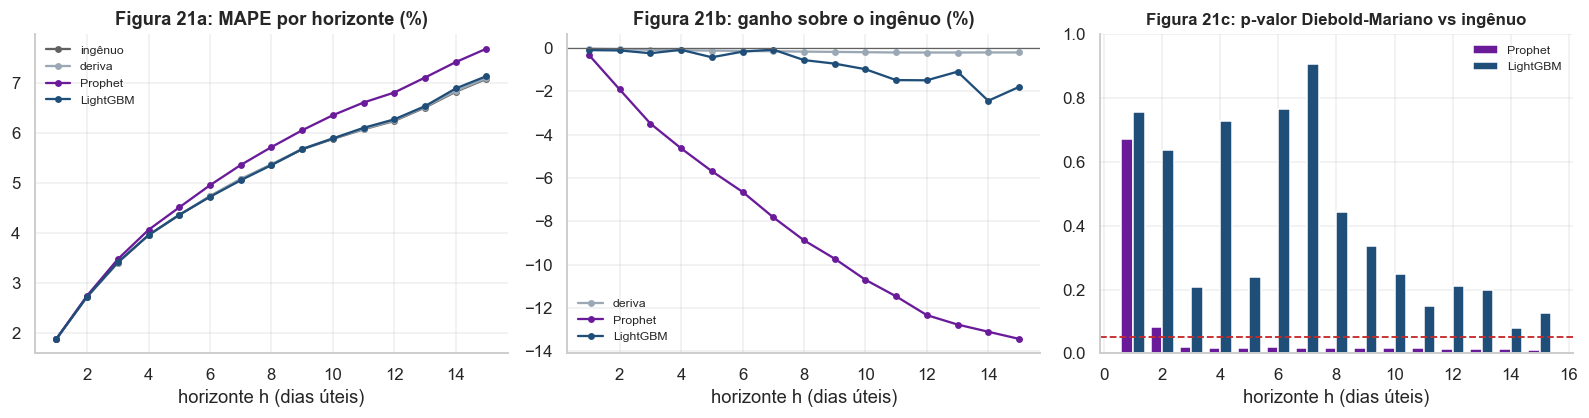

Modelo,h,MAPE (%),MAE (US$),RMSE (US$),Ganho vs ingênuo,DM p-valor,Acerto direção (%),Sempre alta (%)
ingênuo,1,1.88,1.60,2.58,+0.0%,—,—,50.6
deriva,1,1.88,1.60,2.58,-0.0%,0.123,50.6,50.6
Prophet,1,1.88,1.60,2.58,-0.3%,0.671,52.3,50.6
LightGBM,1,1.88,1.60,2.58,-0.1%,0.756,50.6,50.6
ingênuo,5,4.36,3.70,5.62,+0.0%,—,—,50.7
deriva,5,4.36,3.70,5.63,-0.1%,0.160,50.7,50.7
Prophet,5,4.51,3.82,5.77,-5.7%,0.018,48.7,50.7
LightGBM,5,4.36,3.70,5.63,-0.4%,0.240,43.8,50.7
ingênuo,10,5.88,5.02,7.80,+0.0%,—,—,50.8
deriva,10,5.89,5.03,7.81,-0.2%,0.226,50.8,50.8


,MAPE_medio,ganho_medio,horizontes_melhores,horizontes_significativos
Modelo,,,,
ingênuo,5.05,+0.00%,0,0
deriva,5.06,-0.15%,0,0
Prophet,5.38,-8.19%,0,13
LightGBM,5.06,-0.79%,0,0


In [34]:
# 8.7 Teste: uma leitura, configurações congeladas
t0 = time.time()
RES["teste"]["ingênuo"], RES["teste"]["deriva"] = BASE_RES[("teste", "ingênuo")], BASE_RES[("teste", "deriva")]
A_TE, B_TE = PERIODOS["teste"]
RES["teste"]["LightGBM"] = {h: walk_forward(fabrica_lgbm(LGBM_PARAMS, LGBM_CONJ), A_TE, B_TE, h) for h in range(1, H + 1)}
RES["teste"]["Prophet"] = prophet_walk_forward(PROPHET_PARAMS, A_TE, B_TE, list(range(1, H + 1)))
print(f"Teste concluído em {time.time()-t0:.0f} s")
TT = tabela("teste")
figura_modelos(TT, "Figura 21")
display(TT[TT["h"].isin([1, 5, 10, 15])].style.hide(axis="index").format(fmt, na_rep="—"))
resumo_t = TT.groupby("Modelo").agg(MAPE_medio=("MAPE (%)", "mean"), ganho_medio=("Ganho vs ingênuo", "mean"), horizontes_melhores=("Ganho vs ingênuo", lambda s: int((s > 0).sum())),
                                    horizontes_significativos=("DM p-valor", lambda s: int((s < 0.05).sum()))).loc[MODELOS]
display(resumo_t.style.format({"MAPE_medio": "{:.2f}", "ganho_medio": "{:+.2%}"}))

Período,Modelo,VAR_15 real média (%),VAR_15 prevista média (%),DESV_PAD do previsto (%),DESV_PAD do real (%),Correlação previsto x real
validação,Prophet,-0.22,-0.10,+2.53,+8.40,+0.14
validação,LightGBM,-0.22,-0.53,+0.83,+8.40,+0.08
teste,Prophet,+0.92,+0.25,+2.40,+10.73,-0.20
teste,LightGBM,+0.92,-0.31,+0.34,+10.73,-0.18


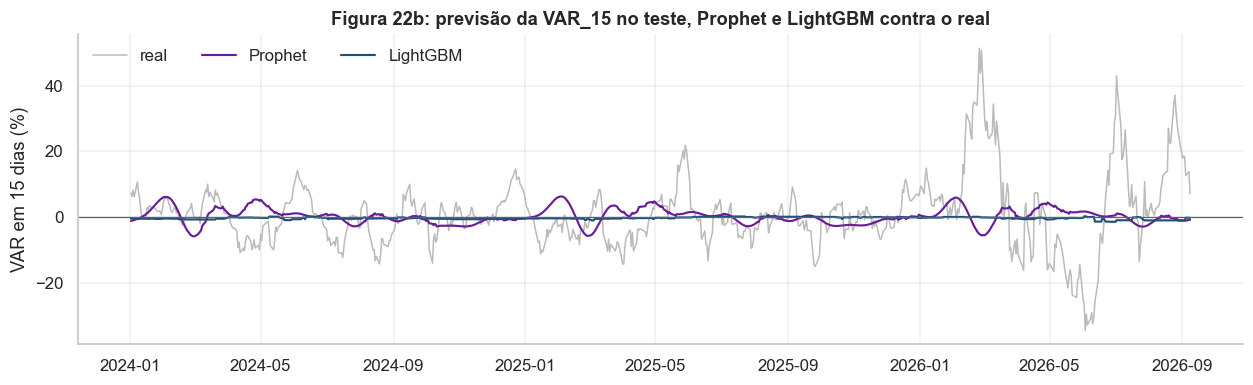

In [35]:
# 8.7b Por que o Prophet erra no teste? Viés e dispersão das previsões em h = 15
linhas = []
for per in ["validação", "teste"]:
    for nome in ["Prophet", "LightGBM"]:
        R = RES[per][nome][H]
        linhas.append({"Período": per, "Modelo": nome, "VAR_15 real média (%)": R["real_var"].mean(), "VAR_15 prevista média (%)": R["pred_var"].mean(),
                       "DESV_PAD do previsto (%)": R["pred_var"].std(), "DESV_PAD do real (%)": R["real_var"].std(), "Correlação previsto x real": R["pred_var"].corr(R["real_var"])})
VIES = pd.DataFrame(linhas)
display(VIES.style.hide(axis="index").format({c: "{:+.2f}" for c in VIES.columns if c not in ("Período", "Modelo")}))
fig, ax = plt.subplots(figsize=(11.5, 3.6))
Rp, Rl = RES["teste"]["Prophet"][H], RES["teste"]["LightGBM"][H]
ax.plot(Rp["data"], Rp["real_var"], color="#bbbbbb", lw=1.0, label="real")
ax.plot(Rp["data"], Rp["pred_var"], color=ROXO, lw=1.4, label="Prophet"); ax.plot(Rl["data"], Rl["pred_var"], color=AZUL, lw=1.4, label="LightGBM")
ax.axhline(0, color=CINZA, lw=0.8); ax.set_ylabel("VAR em 15 dias (%)"); ax.set_title("Figura 22b: previsão da VAR_15 no teste, Prophet e LightGBM contra o real"); ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.show()

### 8.8 Sensibilidade: treinar só com o período limpo (2019-2021)

O treino de 2006-2018 inclui o defeito de datas do Ipeadata (1.5). Aqui o **mesmo LightGBM**, com os mesmos hiperparâmetros, é treinado só com 2019 em diante e avaliado na validação. Só informa; não substitui a decisão.

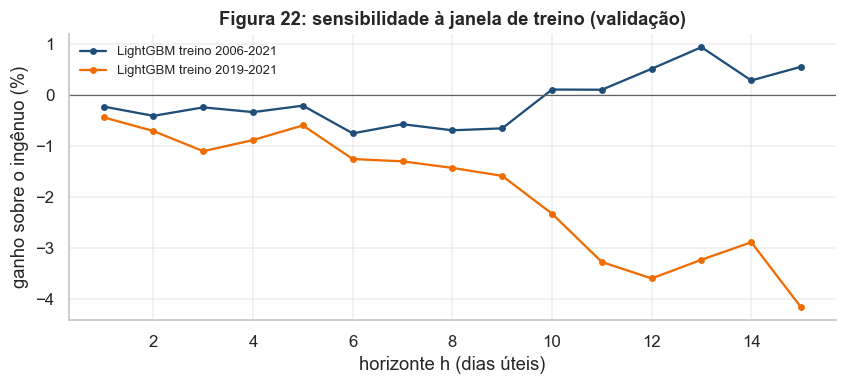

,MAPE_medio,ganho_medio,horizontes_melhores
Variante,,,
LightGBM treino 2006-2021,5.00,-0.11%,6
LightGBM treino 2019-2021,5.09,-1.92%,0


In [36]:
# 8.8 Sensibilidade à janela de treino (só validação)
CURTO = pd.Timestamp("2019-01-01")
RES_CURTO = {h: walk_forward(fabrica_lgbm(LGBM_PARAMS, LGBM_CONJ), V_INI, V_FIM, h, treino_inicio=CURTO) for h in range(1, H + 1)}
linhas = []
for h in range(1, H + 1):
    ing = RES["validação"]["ingênuo"][h]
    for nome, R in [("LightGBM treino 2006-2021", RES["validação"]["LightGBM"][h]), ("LightGBM treino 2019-2021", RES_CURTO[h])]:
        m = metricas(R, ref=ing); linhas.append({"Variante": nome, "h": h, "MAPE (%)": m["MAPE"], "Ganho vs ingênuo": m["ganho_vs_ingenuo"]})
SENS = pd.DataFrame(linhas)
fig, ax = plt.subplots(figsize=(7.8, 3.6))
for nome, cor in [("LightGBM treino 2006-2021", AZUL), ("LightGBM treino 2019-2021", LARANJA)]:
    s = SENS[SENS["Variante"] == nome]; ax.plot(s["h"], s["Ganho vs ingênuo"] * 100, "o-", ms=3.5, color=cor, label=nome)
ax.axhline(0, color=CINZA, lw=0.8); ax.set_xlabel("horizonte h (dias úteis)"); ax.set_ylabel("ganho sobre o ingênuo (%)"); ax.set_title("Figura 22: sensibilidade à janela de treino (validação)")
ax.legend(frameon=False, fontsize=8.5); plt.tight_layout(); plt.show()
display(SENS.groupby("Variante").agg(MAPE_medio=("MAPE (%)", "mean"), ganho_medio=("Ganho vs ingênuo", "mean"), horizontes_melhores=("Ganho vs ingênuo", lambda s: int((s > 0).sum()))).style.format({"MAPE_medio": "{:.2f}", "ganho_medio": "{:+.2%}"}))

## 8.9 Leitura da Fase 3

### O resultado em uma frase
**Nenhum modelo supera o baseline ingênuo ("amanhã = hoje") de forma estatisticamente distinguível, nem na validação nem no teste.** Isso é coerente com a EDA (a direção em 15 dias é quase um cara ou coroa, a sazonalidade é nula e o preço oscila 1,6x mais do que chega), e é o resultado mais importante desta fase.

### O que os números mostram

| | Ingênuo | Deriva | Prophet | LightGBM |
|---|---|---|---|---|
| **Validação**: MAPE médio nos 15 horizontes | 5,01% | 5,02% | 4,99% | 5,00% |
| **Validação**: ganho médio sobre o ingênuo | — | −0,20% | −0,33% | −0,11% |
| **Validação**: horizontes com ganho / significativos | — | 0 / 0 | 4 / 0 | 6 / 0 |
| **Teste**: MAPE médio nos 15 horizontes | 5,05% | 5,06% | **5,38%** | 5,06% |
| **Teste**: ganho médio sobre o ingênuo | — | −0,15% | **−8,19%** | −0,79% |
| **Teste**: horizontes com ganho / significativos | — | 0 / 0 | 0 / **13 (piores)** | 0 / 0 |
| **Teste**: MAPE em h = 15 (ingênuo 7,08%) | — | 7,10% | 7,68% | 7,13% |

**1. Na validação há empate técnico.** As diferenças são de centésimos de ponto de MAPE. O LightGBM tem ganho positivo em 6 dos 15 horizontes, o melhor em h = 15 (+0,6%), mas nenhum horizonte tem diferença significativa (nenhum com p < 0,05).

**2. No teste o Prophet piora de forma significativa.** Em 13 dos 15 horizontes ele é pior que o ingênuo com p < 0,05 (−13,4% em h = 15). A tendência e a sazonalidade que ele aprendeu até 2023 **não se sustentam em 2024-2026**: a correlação entre o previsto e o real, que era de +0,14 na validação, foi de **−0,20** no teste. Isso é coerente com a ausência de sazonalidade verdadeira encontrada na EDA (força sazonal de 0,02).

**3. O LightGBM praticamente "se recusou" a prever.** O Optuna testou 60 combinações e só 4 ficaram melhores que o ingênuo, a melhor com razão de 0,9989, ou seja, 0,1% melhor, dentro do ruído. Os hiperparâmetros escolhidos ficaram nos **limites** do espaço de busca (41 árvores, taxa de aprendizado de 0,006): o melhor que a busca encontrou foi um modelo quase parado. O desvio padrão das suas previsões em h = 15 é de 0,34% contra 10,7% do que realmente aconteceu. No teste, a correlação previsto × real também é negativa (−0,18) e o acerto de direção (43,8% a 50,6%) fica abaixo de apostar sempre na alta (50,4% a 50,8%).

**4. As escolhas de modelagem não fizeram diferença.** Features relativas (mediana 1,0081) contra em nível (1,0074) e perda de Huber contra quadrática: nenhuma separa dos demais. Sem regressores, o Prophet foi melhor (a busca escolheu `reg = False`).

**5. A janela de treino longa é melhor.** Treinar só com 2019-2021 piora (ganho médio de −1,92% contra −0,11% do treino completo, 0 horizontes com ganho). Mantemos 2006-2021 como você definiu.

### Ressalvas
- A validação é **levemente otimista** (o Optuna ajustou nela). Mesmo assim, não houve ganho.
- Com ~500 a ~700 origens que se sobrepõem, o teste de Diebold-Mariano tem pouco poder para detectar ganhos pequenos. Um ganho real de 1% ou 2% passaria despercebido. O que dá para afirmar é que **não há evidência de ganho**, e não que ele não exista.
- O teste foi lido **uma única vez**, com tudo congelado antes.

### O que isso significa para o produto
Prever o **nível** do Brent em 15 dias melhor que o último preço não está ao alcance destes dados. O que a EDA indicou como previsível é a **instabilidade** (o tamanho dos movimentos persiste: autocorrelação de |VAR| de 0,40 em 1 dia) e, portanto, a **faixa de incerteza**. O valor para a tomada de decisão está em dizer **"o preço de hoje, mais uma faixa honesta e calibrada que se alarga quando o mercado está instável"**.

### Para o seu portão (Fase 3)
**Proposta para a Fase 4 (comparação, SHAP e incerteza), em vez de tentar forçar um ganho que os dados não dão:**
1. **Central:** manter o LightGBM como candidato (empata com o ingênuo, tem as 25 features e permite o SHAP), apresentando-o com a ressalva de que a média prevista é muito próxima do preço de hoje.
2. **Faixa:** calibrar as faixas de 80% e 95% por **regime de DESV_PAD 30D** (quantis condicionais ou LightGBM quantílico), que é onde a EDA achou sinal. Medir a cobertura em validação e teste.
3. **SHAP:** aplicar ao LightGBM de média (para mostrar por que ele quase não se afasta do ingênuo) e ao modelo de faixa (onde esperamos mais peso para DESV_PAD e volatilidade).
4. **No app:** mostrar o preço atual, a previsão com a faixa e uma mensagem clara sobre o que o modelo sabe e o que não sabe.

Alternativas, se preferir: (a) tentar uma modelagem mais agressiva do nível (por exemplo, relaxar os limites do Optuna), sabendo que o resultado mais provável é um modelo pior; ou (b) mudar o alvo para prever diretamente a instabilidade futura.